# H4 – Różnice między platformami: YouTube vs Wykop vs Bluesky

**H4:** zależność między wydarzeniami a poziomem mowy nienawiści różni się między YouTube, Wykopem i Bluesky.

Notebook łączy komentarze ze **wszystkich platform i wszystkich wydarzeń** i odpowiada na pytania:

1. Jaki jest **poziom** hate / hate_migrant / migrant na każdej platformie i jak zmienia się po wydarzeniu?
2. **Gdzie reakcja była silniejsza** – czy to samo wydarzenie podbiło hejt bardziej na jednej platformie niż na drugiej?
3. **Test H4**: czy efekt wydarzeń (OR po vs przed) różni się między platformami – łącznie i w parach?
4. Czy **typ wydarzenia** różnicuje hejt i czy dzieje się to tak samo na każdej platformie?
5. **Przebieg w czasie** na wspólnej osi dla platform.
6. **Liczba komentarzy**: czy po zsumowaniu komentarzy ze wszystkich platform widać ogólny przyrost hejtu (także w liczbach bezwzględnych)?
7. **Słownictwo**: czym różni się język hejtu między platformami, kogo się obraża i co rośnie po wydarzeniu?

Platformę bez danych `labeled` (na razie Bluesky) notebook pomija i wypisuje powód – po dodaniu
`data/interim/bluesky/<data>_<wydarzenie>/labeled/comments.csv` wystarczy uruchomić go ponownie.

### Jak łączone są dane i dlaczego definicje są „zharmonizowane”

Dla każdej platformy i wydarzenia: **bazą są wszystkie komentarze z `clean/comments.csv`**, do których doklejany jest
`labeled/comments.csv` (LEFT JOIN, jak w notebookach YouTube). Mianownik odsetków = wszystkie komentarze.

Platformy były etykietowane różnie:

| | YouTube (`scripts/topic_sample.py`) | Wykop (LLM na wszystkich komentarzach) |
|---|---|---|
| co jest w `labeled` | tylko komentarze, które przeszły **regex migracyjny** i LLM uznał za **o migracji** (+ slury 1/1) | wszystkie komentarze (lub wszystkie z `topic/`) |
| hate poza tematem migracji | **nieznany** (nie był oceniany) | znany (`llm_is_hate_general`) |

Gdyby porównać „surowe” etykiety, Wykop miałby hejt liczony na wszystkich komentarzach, a YouTube tylko w wąskim
podzbiorze migracyjnym – różnice wynikałyby z procedury, a nie z platformy. Dlatego w tym notebooku **każda platforma
przechodzi przez ten sam lejek**:

| etykieta | definicja (wszystkie platformy) |
|---|---|
| `migrant` | komentarz przeszedł regex migracyjny (`topic/` lub obecność w `labeled` dla YT) **i** LLM: o migracji (lub slur 1/1) |
| `hate_migrant` | `migrant` ∧ (LLM/model: hate wobec migrantów ∨ człowiek ∨ slur 1/1) |
| `hate` | `migrant` ∧ (LLM/model: hate ∨ człowiek ∨ `hate_migrant`) – czyli **hejt w dyskusji o migracji** |
| `hate_migrant \| migrant` | odsetek hejtu wobec migrantów **wśród** komentarzy o migracji – najlepiej porównywalna miara między platformami |

Konsekwencja: odsetki dla Wykopu są tu niższe niż w `wykop/all_events_hate_analysis.ipynb` (tam mianownikiem był `labeled`,
a `hate` obejmował też hejt poza migracją). **Poziomy** (`hate`, `hate_migrant`, `migrant`) zależą od tego, ile treści
nie-migracyjnych jest na platformie (YouTube = głównie newsowe kanały o wszystkim), więc między platformami porównujemy przede
wszystkim **zmiany** (OR po vs przed) oraz `hate_migrant | migrant`.

**Okno czasowe:** YouTube ma komentarze tylko z dni −7..18, Wykop ±28. Efekt „po vs przed” zależy od długości okna, więc
domyślnie (`COMMON_WINDOW = True`) każde wydarzenie jest przycinane do **wspólnego zakresu dni dostępnego na wszystkich platformach**.

In [1]:
import json
import re
from collections import Counter
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import confint_proportions_2indep

# katalog projektu = pierwszy katalog w górę, który zawiera events.json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "events.json").exists())

# ---- konfiguracja ----
PLATFORMS = ["youtube", "wykop", "bluesky"]
EVENTS = json.loads((ROOT / "events.json").read_text(encoding="utf-8"))

# typ i zasięg wydarzenia – PRZYPISANE RĘCZNIE (jak w wykop/all_events_hate_analysis.ipynb)
EVENT_META = {
    "Pakt_Azyl_PE":               ("polityka / prawo",   "UE / zagranica"),
    "Smierc_Zolnierza":           ("przemoc / incydent", "Polska"),
    "Bojka_Srem":                 ("przemoc / incydent", "Polska"),
    "Strategia_Migracyjna":       ("polityka / prawo",   "Polska"),
    "Dezinformacja_Krakow":       ("dezinformacja",      "Polska"),
    "Ceuta_Masowe_Przekroczenie": ("kryzys graniczny",   "UE / zagranica"),
    "Atak_Kamienna_Gora":         ("przemoc / incydent", "Polska"),
}
COMMON_WINDOW = True  # przytnij każde wydarzenie do zakresu relative_day wspólnego dla wszystkich platform
POST_FROM_DAY = 0     # od którego relative_day liczymy okres "po"
MIN_N_PERIOD = 30     # min. liczba komentarzy w okresie (przed/po), by liczyć OR dla danej platformy i wydarzenia
MIN_THREADS_PERIOD = 5  # min. liczba wątków (filmów/znalezisk) w okresie; mniej = brak wiarygodnego punktu odniesienia
MIN_DAILY_N = 10      # min. liczba komentarzy w dniu, by liczyć dzienny odsetek
ROLL_DAYS = 5         # wygładzanie przebiegów dziennych
TOP_N_WORDS = 15
ALPHA = 0.05

# kolumny z etykietami – różne nazwy w zależności od skryptu, który etykietował (pierwsza obecna wygrywa przez OR)
HATE_MIGRANT_COLS = ["llm_is_hate_migrants", "model_hate_migrants", "human_hate_migrants"]
HATE_COLS = ["llm_is_hate_general", "llm_is_hate", "model_hate", "human_hate"]
CLEAN_COLS = ["comment_id", "relative_day", "created_date", "thread_id", "author_id", "likes", "text"]

LABELS = ["hate", "hate_migrant", "migrant"]
LABEL_SETS = {"hate": ("hate", None), "hate_migrant": ("hate_migrant", None), "migrant": ("migrant", None),
              "hate_migrant | migrant": ("hate_migrant", "migrant")}
LABEL_NAMES = {"hate": "hate (w dyskusji o migracji)", "hate_migrant": "hate wobec migrantów", "migrant": "o migracji",
               "hate_migrant | migrant": "hate wobec migrantów wśród komentarzy o migracji"}
SHORT_NAMES = {**LABEL_NAMES, "hate": "hate", "hate_migrant | migrant": "hate_migrant wśród o migracji"}

# kolor = platforma; typ wydarzenia = drugi zestaw slotów (używany tylko tam, gdzie nie ma platform)
PLATFORM_COLORS = {"youtube": "#eb6834", "wykop": "#2a78d6", "bluesky": "#1baf7a"}
TYPE_ORDER = list(dict.fromkeys(t for t, _ in EVENT_META.values()))
TYPE_COLORS = dict(zip(TYPE_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
TYPE_MARKERS = dict(zip(TYPE_ORDER, ["o", "s", "D", "^", "v"]))
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#8a8984"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.figsize": (13, 4.5), "figure.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 250)


def fmt_p(t, digits=3):
    # kolumny z p-value jako tekst w notacji naukowej (round() zamieniłby małe p na 0)
    t = t.copy()
    for c in t.columns:
        if c == "p" or c.startswith("p ") or c.startswith("p("):
            t[c] = t[c].map(lambda v: "" if pd.isna(v) else f"{v:.3g}")
    return t.round(digits)


def holm(p):
    # korekta Holma, która przepuszcza NaN (np. brak danych dla platformy)
    p = pd.Series(p, dtype=float)
    out = pd.Series(np.nan, index=p.index)
    ok = p.notna()
    if ok.any():
        out[ok] = multipletests(p[ok], method="holm")[1]
    return out


def platform_legend(fig, extra=(), **kw):
    handles = [plt.Line2D([], [], marker="o", ls="", ms=9, color=PLATFORM_COLORS[p]) for p in PL]
    labels = list(PL)
    for h, l in extra:
        handles.append(h)
        labels.append(l)
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    fig.legend(handles, labels, loc="upper center", ncol=len(labels), bbox_to_anchor=(0.5, 1.0), **kw)


def type_legend(fig, extra=(), **kw):
    handles = [plt.Line2D([], [], marker=TYPE_MARKERS[t], ls="", ms=9, color=TYPE_COLORS[t]) for t in TYPE_ORDER]
    labels = list(TYPE_ORDER)
    for h, l in extra:
        handles.append(h)
        labels.append(l)
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    fig.legend(handles, labels, loc="upper center", ncol=len(labels), bbox_to_anchor=(0.5, 1.0), **kw)

## 0. Wczytanie danych

In [2]:
def to_bool(s):
    return s.fillna(False).astype(str).str.strip().str.lower().isin(["true", "1", "1.0"])


def flag(d, cols):
    # OR po wszystkich kolumnach z listy, które istnieją w danych
    out = pd.Series(False, index=d.index)
    for c in cols:
        if c in d.columns:
            out |= to_bool(d[c])
    return out


def load_event(platform, event):
    event_dir = ROOT / "data" / "interim" / platform / f"{pd.Timestamp(EVENTS[event]):%Y-%m-%d}_{event}"
    labeled_file = event_dir / "labeled" / "comments.csv"
    if not labeled_file.exists():
        return None, "brak labeled/comments.csv"

    clean = pd.read_csv(event_dir / "clean" / "comments.csv", encoding="utf-8-sig", dtype={"comment_id": str},
                        usecols=lambda c: c in CLEAN_COLS).drop_duplicates("comment_id")
    labeled = (pd.read_csv(labeled_file, encoding="utf-8-sig", dtype={"comment_id": str})
               .drop(columns=["text", "event", "post_id"], errors="ignore").drop_duplicates("comment_id"))
    # LEFT JOIN – bazą są wszystkie komentarze z clean/comments.csv
    d = clean.merge(labeled, on="comment_id", how="left", indicator=True)
    in_labeled = d.pop("_merge") == "both"

    slur = flag(d, ["hate_auto"]) & flag(d, ["hate_migrants_auto"])  # slur 1/1 ze słownika
    if "llm_is_about_migration" in labeled.columns:
        # LLM oceniał wszystkie komentarze (Wykop) -> ten sam lejek co YT: regex (topic/) + LLM "o migracji"
        topic_file = event_dir / "topic" / "comments.csv"
        in_topic = (d["comment_id"].isin(pd.read_csv(topic_file, encoding="utf-8-sig", dtype={"comment_id": str},
                                                     usecols=["comment_id"])["comment_id"])
                    if topic_file.exists() else pd.Series(True, index=d.index))
        migrant = in_labeled & in_topic & (flag(d, ["llm_is_about_migration"]) | slur)
    else:
        # labeled zawiera tylko komentarze po regexie i z LLM "o migracji" (YouTube, scripts/topic_sample.py)
        migrant = in_labeled
    d["migrant"] = migrant
    d["hate_migrant"] = migrant & (flag(d, HATE_MIGRANT_COLS) | slur)
    d["hate"] = migrant & (flag(d, HATE_COLS) | d["hate_migrant"])

    d = d[["comment_id", "relative_day", "thread_id", "author_id", "text", "migrant", "hate_migrant", "hate"]].copy()
    d["text"] = d["text"].fillna("").astype(str)
    d["platform"], d["event"] = platform, event
    d["typ"], d["zasieg"] = EVENT_META[event]
    d["pe"] = platform + ":" + event
    # wątki numerujemy w obrębie platformy i wydarzenia, żeby klastry się nie zlały
    d["thread"] = d["pe"] + ":" + d["thread_id"].astype(str)
    return d, None


frames, skipped = [], {}
for platform in PLATFORMS:
    for event in EVENT_META:
        d, why = load_event(platform, event)
        if d is None:
            skipped[(platform, event)] = why
        else:
            frames.append(d)
all_df = pd.concat(frames, ignore_index=True)
PL = [p for p in PLATFORMS if p in set(all_df["platform"])]
EVENT_ORDER = [e for e in EVENT_META if e in set(all_df["event"])]  # chronologicznie

for p in PLATFORMS:
    miss = [e for (pp, e) in skipped if pp == p]
    if len(miss) == len(EVENT_META):
        print(f"POMINIĘTA PLATFORMA: {p} – {skipped[(p, miss[0])]} we wszystkich wydarzeniach")
    elif miss:
        print(f"{p}: pominięte wydarzenia – " + ", ".join(f"{e} ({skipped[(p, e)]})" for e in miss))
print("platformy w analizie:", PL)

POMINIĘTA PLATFORMA: bluesky – brak labeled/comments.csv we wszystkich wydarzeniach
platformy w analizie: ['youtube', 'wykop']


### Wspólne okno czasowe

In [3]:
rng = all_df.groupby(["event", "platform"])["relative_day"].agg(["min", "max"]).unstack("platform")
WINDOW = pd.DataFrame({"od": rng["min"].max(axis=1), "do": rng["max"].min(axis=1)}).reindex(EVENT_ORDER).astype(int)
if not COMMON_WINDOW:
    WINDOW = pd.DataFrame({"od": rng["min"].min(axis=1), "do": rng["max"].max(axis=1)}).reindex(EVENT_ORDER).astype(int)
display(pd.concat([rng.reindex(EVENT_ORDER), WINDOW.set_axis(pd.MultiIndex.from_product([["okno analizy"], WINDOW.columns]), axis=1)], axis=1))

n_before = len(all_df)
lo, hi = all_df["event"].map(WINDOW["od"]), all_df["event"].map(WINDOW["do"])
all_df = all_df[all_df["relative_day"].between(lo, hi)].reset_index(drop=True)
all_df["okres"] = np.where(all_df["relative_day"] >= POST_FROM_DAY, "po", "przed")
all_df["po"] = (all_df["okres"] == "po").astype(int)
print(f"po przycięciu do okna: {len(all_df):,} z {n_before:,} komentarzy")

# para platforma–wydarzenie bez wiarygodnego okresu przed/po (np. komentarze "przed" z jednego filmu) jest wykluczana
per = all_df.groupby(["pe", "okres"]).agg(n=("comment_id", "size"), wątki=("thread", "nunique")).unstack("okres")
per = per.reindex(columns=pd.MultiIndex.from_product([["n", "wątki"], ["przed", "po"]])).fillna(0).astype(int)
bad = per[(per["n"].min(axis=1) < MIN_N_PERIOD) | (per["wątki"].min(axis=1) < MIN_THREADS_PERIOD)]
if len(bad):
    print(f"\nWYKLUCZONE (< {MIN_N_PERIOD} komentarzy lub < {MIN_THREADS_PERIOD} wątków w okresie przed/po):")
    display(bad)
    all_df = all_df[~all_df["pe"].isin(bad.index)].reset_index(drop=True)

min           max         okno analizy    
                           wykop youtube wykop youtube           od  do
event                                                                  
Pakt_Azyl_PE                 -29      -7    28      18           -7  18
Smierc_Zolnierza             -28      -5    28      18           -5  18
Bojka_Srem                   -28      -7    28      18           -7  18
Strategia_Migracyjna         -28      -7    28      18           -7  18
Dezinformacja_Krakow         -28      -7    28      18           -7  18
Ceuta_Masowe_Przekroczenie   -28      -7    28      18           -7  18
Atak_Kamienna_Gora           -28      -7    28      18           -7  18

po przycięciu do okna: 668,806 z 750,357 komentarzy



WYKLUCZONE (< 30 komentarzy lub < 5 wątków w okresie przed/po):


n        wątki     
                         przed     po przed   po
pe                                              
youtube:Smierc_Zolnierza    99  37733     1  229

In [4]:
overview = (all_df.groupby(["platform", "event"])
            .agg(komentarze=("comment_id", "size"), przed=("po", lambda s: int((s == 0).sum())), po=("po", "sum"),
                 migrant=("migrant", "sum"), hate=("hate", "sum"), hate_migrant=("hate_migrant", "sum"),
                 wątki=("thread", "nunique"))
            .reindex(pd.MultiIndex.from_product([PL, EVENT_ORDER], names=["platform", "event"])).dropna(how="all")
            .astype(int))
overview.insert(0, "typ", [EVENT_META[e][0] for _, e in overview.index])
display(overview)
display(all_df.groupby("platform")[["migrant", "hate", "hate_migrant"]].agg(["sum", "mean"])
        .rename(columns={"sum": "n", "mean": "odsetek"}).reindex(PL).round(4))

typ  komentarze  przed     po  migrant  hate  hate_migrant  wątki
platform event                                                                                                       
youtube  Pakt_Azyl_PE                  polityka / prawo       90752  35967  54785     1867  1109           907    509
         Bojka_Srem                  przemoc / incydent      109844  27959  81885     2519  1925          1666    857
         Strategia_Migracyjna          polityka / prawo      117539  25699  91840     4862  2927          2074    892
         Dezinformacja_Krakow             dezinformacja       58140  17573  40567     2289  1432          1047    663
         Ceuta_Masowe_Przekroczenie    kryzys graniczny       67113  16961  50152     6243  3950          3367    649
         Atak_Kamienna_Gora          przemoc / incydent      109441  14833  94608     5179  3499          3056   1004
wykop    Pakt_Azyl_PE                  polityka / prawo       12149   3458   8691     3233  1360          1343    591
         Smierc_Zolnierza            przemoc / incydent       11437   2202   9235     4920  1941          1941    265
         Bojka_Srem                  przemoc / incydent       12326   3408   8918     3993  1401          1400    616
         Strategia_Migracyjna          polityka / prawo       10999   3227   7772     4627  1759          1759    455
         Dezinformacja_Krakow             dezinformacja        8932   2468   6464     2424  1018          1018    786
         Ceuta_Masowe_Przekroczenie    kryzys graniczny       11783   3579   8204     4549  2029          2029    828
         Atak_Kamienna_Gora          przemoc / incydent       10519   2924   7595     3391  1514          1514    824

migrant           hate         hate_migrant        
               n odsetek      n odsetek            n odsetek
platform                                                    
youtube    22959  0.0415  14842  0.0268        12117  0.0219
wykop      27137  0.3473  11022  0.1410        11004  0.1408

## 1. Poziom i zmiana: przed vs po na każdej platformie

Dla każdej platformy, wydarzenia i etykiety: odsetek przed i po, różnica w pp z 95% CI (Newcombe),
Cohen's h oraz **OR z regresji logistycznej z błędami klastrowanymi po wątku** (`y ~ po`) – ten sam test co w notebookach
pojedynczych platform. Gdy w którymś okresie jest 0 przypadków (małe próby, np. Bluesky), OR liczony jest
z poprawką 0.5 (Woolf, bez klastrów). Korekta Holma – w obrębie platformy i etykiety.

In [5]:
def woolf(k1, n1, k2, n2):
    a, b, c, e = k2 + 0.5, n2 - k2 + 0.5, k1 + 0.5, n1 - k1 + 0.5
    lor, se = np.log(a * e / (b * c)), np.sqrt(1 / a + 1 / b + 1 / c + 1 / e)
    return lor, se, 2 * stats.norm.sf(abs(lor / se))


def event_effect(d, col):
    pre, post = d.loc[d["okres"] == "przed", col], d.loc[d["okres"] == "po", col]
    k1, n1, k2, n2 = int(pre.sum()), len(pre), int(post.sum()), len(post)
    out = {"n przed": n1, "n po": n2, "k przed": k1, "k po": k2}
    if min(n1, n2) < MIN_N_PERIOD or k1 + k2 == 0:
        return {**out, "przed %": 100 * k1 / n1 if n1 else np.nan, "po %": 100 * k2 / n2 if n2 else np.nan}
    p1, p2 = k1 / n1, k2 / n2
    lo, hi = confint_proportions_2indep(k2, n2, k1, n1, method="newcomb")
    if 0 < k1 < n1 and 0 < k2 < n2:
        try:
            m = smf.logit("y ~ po", data=d.assign(y=d[col].astype(int))).fit(
                disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(d["thread"])[0]})
            b, se, p = m.params["po"], m.bse["po"], m.pvalues["po"]
        except Exception:
            b, se, p = woolf(k1, n1, k2, n2)
    else:
        b, se, p = woolf(k1, n1, k2, n2)
    return {**out, "przed %": 100 * p1, "po %": 100 * p2, "różnica pp": 100 * (p2 - p1),
            "CI lo pp": 100 * lo, "CI hi pp": 100 * hi,
            "Cohen h": 2 * np.arcsin(np.sqrt(p2)) - 2 * np.arcsin(np.sqrt(p1)),
            "log OR": b, "se": se, "OR": np.exp(b), "OR lo": np.exp(b - 1.96 * se), "OR hi": np.exp(b + 1.96 * se),
            "p": p}


def effects(df, by=("platform", "event")):
    rows = []
    for keys, d in df.groupby(list(by), sort=False):
        keys = dict(zip(by, keys if isinstance(keys, tuple) else (keys,)))
        ev = keys["event"]
        for name, (col, cond) in LABEL_SETS.items():
            dd = d[d[cond]] if cond else d
            rows.append({"etykieta": name, **keys, "typ": EVENT_META[ev][0], "zasieg": EVENT_META[ev][1],
                         **event_effect(dd, col)})
    e = pd.DataFrame(rows)
    group = ["etykieta", "platform"] if "platform" in by else ["etykieta"]
    e["p (Holm)"] = e.groupby(group)["p"].transform(holm)
    e["istotne"] = e["p (Holm)"] < ALPHA
    return e


eff = effects(all_df)

show = ["przed %", "po %", "różnica pp", "OR", "OR lo", "OR hi", "p (Holm)", "istotne"]
for name in LABEL_SETS:
    print(f"\n=== {LABEL_NAMES[name]} ===")
    t = eff[eff["etykieta"] == name].pivot(index="event", columns="platform", values=show).reindex(EVENT_ORDER)
    t = t.reindex(columns=pd.MultiIndex.from_product([show, PL]))
    t.insert(0, ("typ", ""), [EVENT_META[e][0] for e in t.index])
    for c in [c for c in t.columns if c[0] == "p (Holm)"]:
        t[c] = t[c].map(lambda v: "" if pd.isna(v) else f"{v:.3g}")
    display(t.round(2))


=== hate (w dyskusji o migracji) ===


typ   przed %                 po %            różnica pp                  OR               OR lo               OR hi           p (Holm)           istotne       
                                                 youtube      wykop   youtube      wykop    youtube     wykop   youtube     wykop   youtube     wykop   youtube     wykop  youtube     wykop youtube  wykop
event                                                                                                                                                                                                      
Pakt_Azyl_PE                  polityka / prawo  0.589429   6.072874  1.637309  13.232079    1.04788  7.159205  2.807381  2.358662  1.548707  1.676829  5.089009  3.317741  0.00402  5.77e-06    True   True
Smierc_Zolnierza            przemoc / incydent       NaN  19.527702       NaN  16.361668        NaN -3.166035       NaN  0.806153       NaN  0.598788       NaN   1.08533              0.778     NaN  False
Bojka_Srem                  przemoc / incydent  1.655996  10.299296  1.785431   11.77394   0.129435  1.474645  1.079582  1.162287  0.592742  0.852089  1.966281  1.585411    0.802         1   False  False
Strategia_Migracyjna          polityka / prawo  1.381377  15.804152  2.800523   16.07051   1.419146  0.266357  2.056942  1.020081   0.98003  0.798551  4.317225  1.303066    0.283         1   False  False
Dezinformacja_Krakow             dezinformacja  3.545211  10.494327  1.994232  11.741955   -1.55098  1.247628  0.553612  1.134703  0.236548  0.900986  1.295662  1.429045    0.519         1   False  False
Ceuta_Masowe_Przekroczenie    kryzys graniczny  8.142209  18.217379  5.122428  16.784495  -3.019781 -1.432884  0.609096  0.905481  0.271414  0.715935  1.366911  1.145209    0.519         1   False  False
Atak_Kamienna_Gora          przemoc / incydent  1.631497  17.783858  3.442626  13.087558   1.811129   -4.6963  2.149682  0.696158  0.972182  0.553018  4.753359  0.876347    0.283    0.0123   False   True


=== hate wobec migrantów ===


typ   przed %                 po %            różnica pp                  OR               OR lo               OR hi           p (Holm)           istotne       
                                                 youtube      wykop   youtube      wykop    youtube     wykop   youtube     wykop   youtube     wykop   youtube     wykop  youtube     wykop youtube  wykop
event                                                                                                                                                                                                      
Pakt_Azyl_PE                  polityka / prawo  0.500459   6.015038  1.327006  13.059487   0.826547  7.044449   2.67379  2.347059  1.503638  1.668404   4.75457  3.301769  0.00487  6.72e-06    True   True
Smierc_Zolnierza            przemoc / incydent       NaN  19.527702       NaN  16.361668        NaN -3.166035       NaN  0.806153       NaN  0.598788       NaN   1.08533              0.778     NaN  False
Bojka_Srem                  przemoc / incydent  1.473586  10.299296  1.531416  11.762727    0.05783  1.463431  1.039855  1.161032  0.571337  0.851138  1.892574  1.583757    0.898         1   False  False
Strategia_Migracyjna          polityka / prawo  1.272423  15.804152  1.902221   16.07051   0.629798  0.266357  1.504558  1.020081  0.696624  0.798551  3.249521  1.303066    0.597         1   False  False
Dezinformacja_Krakow             dezinformacja  2.566437  10.494327  1.469174  11.741955  -1.097263  1.247628  0.566082  1.134703  0.265852  0.900986  1.205365  1.429045    0.484         1   False  False
Ceuta_Masowe_Przekroczenie    kryzys graniczny  7.564412  18.217379  4.155368  16.784495  -3.409045 -1.432884  0.529792  0.905481  0.237315  0.715935  1.182732  1.145209    0.484         1   False  False
Atak_Kamienna_Gora          przemoc / incydent  1.051709  17.783858   3.06528  13.087558   2.013571   -4.6963  2.975113  0.696158  1.373633  0.553018  6.443716  0.876347   0.0285    0.0123    True   True


=== o migracji ===


typ    przed %                 po %            różnica pp                   OR               OR lo               OR hi           p (Holm)           istotne       
                                                  youtube      wykop   youtube      wykop    youtube      wykop   youtube     wykop   youtube     wykop   youtube     wykop  youtube     wykop youtube  wykop
event                                                                                                                                                                                                        
Pakt_Azyl_PE                  polityka / prawo   0.728446  15.384615  2.929634  31.078127   2.201189  15.693511   4.11296   2.48005  1.759957  1.725545  9.611845  3.564467  0.00656  6.45e-06    True   True
Smierc_Zolnierza            przemoc / incydent        NaN  46.276113       NaN  42.241473        NaN   -4.03464       NaN   0.84905       NaN  0.615176       NaN  1.171837                  1     NaN  False
Bojka_Srem                  przemoc / incydent    1.96359  26.525822  2.405813  34.637811   0.442223    8.11199  1.230764  1.467877  0.681773    1.0717  2.221822   2.01051        1    0.0839   False  False
Strategia_Migracyjna          polityka / prawo   2.159617  40.192129  4.689678  42.846114   2.530061   2.653985  2.229176  1.115535  1.003366  0.817669  4.952557  1.521907    0.245         1   False  False
Dezinformacja_Krakow             dezinformacja   5.149946  26.094003   3.41164  27.537129  -1.738306   1.443125  0.650539  1.076322  0.249148  0.781647  1.698596  1.482086        1         1   False  False
Ceuta_Masowe_Przekroczenie    kryzys graniczny  11.267024  38.278849  8.637741  38.749391  -2.629283   0.470542  0.744576  1.020069  0.319004  0.796262  1.737892  1.306782        1         1   False  False
Atak_Kamienna_Gora          przemoc / incydent   2.912425  40.287278  5.017546  29.137591   2.105121 -11.149687   1.76099  0.609448  0.781333  0.445199  3.968968  0.834294    0.689     0.012   False   True


=== hate wobec migrantów wśród komentarzy o migracji ===


typ    przed %                  po %            różnica pp                  OR               OR lo               OR hi            p (Holm)        istotne       
                                                  youtube      wykop    youtube      wykop    youtube     wykop   youtube     wykop   youtube     wykop   youtube     wykop   youtube  wykop youtube  wykop
event                                                                                                                                                                                                      
Pakt_Azyl_PE                  polityka / prawo   68.70229  39.097744   45.29595  42.021474  -23.40634  2.923729  0.377208  1.128979  0.192573  0.899672  0.738869   1.41673    0.0179      1    True  False
Smierc_Zolnierza            przemoc / incydent        NaN  42.198234        NaN  38.733658        NaN -3.464576       NaN  0.865991       NaN  0.660161       NaN  1.135996                1     NaN  False
Bojka_Srem                  przemoc / incydent  75.045537  38.827434  63.654822   33.95921 -11.390715 -4.868224  0.582382  0.810146  0.305267  0.641623  1.111056  1.022933     0.202  0.538   False  False
Strategia_Migracyjna          polityka / prawo  58.918919  39.321511  40.561876  37.507508 -18.357043 -1.814004  0.475817  0.926179  0.327138  0.739471  0.692069  1.160029  0.000613      1    True  False
Dezinformacja_Krakow             dezinformacja  49.834254  40.217391  43.063584  42.640449   -6.77067  2.423058  0.761376  1.105037  0.362512  0.824629  1.599101  1.480797     0.471      1   False  False
Ceuta_Masowe_Przekroczenie    kryzys graniczny  67.137624  47.591241   48.10711  43.315508 -19.030514 -4.275733  0.453769  0.841504  0.225594  0.679987  0.912727  1.041386    0.0801  0.675   False  False
Atak_Kamienna_Gora          przemoc / incydent  36.111111  44.142615  61.091216  44.916403  24.980104  0.773788  2.777893  1.031823  1.437576  0.825247  5.367851   1.29011    0.0118      1    True  False

### Wykres: przed → po dla każdego wydarzenia i platformy

Kółko puste = odsetek **przed**, pełne = **po**; kreska łączy je, kolor = platforma. Skala logarytmiczna – poziomy
na platformach różnią się nawet 10×, a na skali log ta sama *względna* zmiana ma tę samą długość.

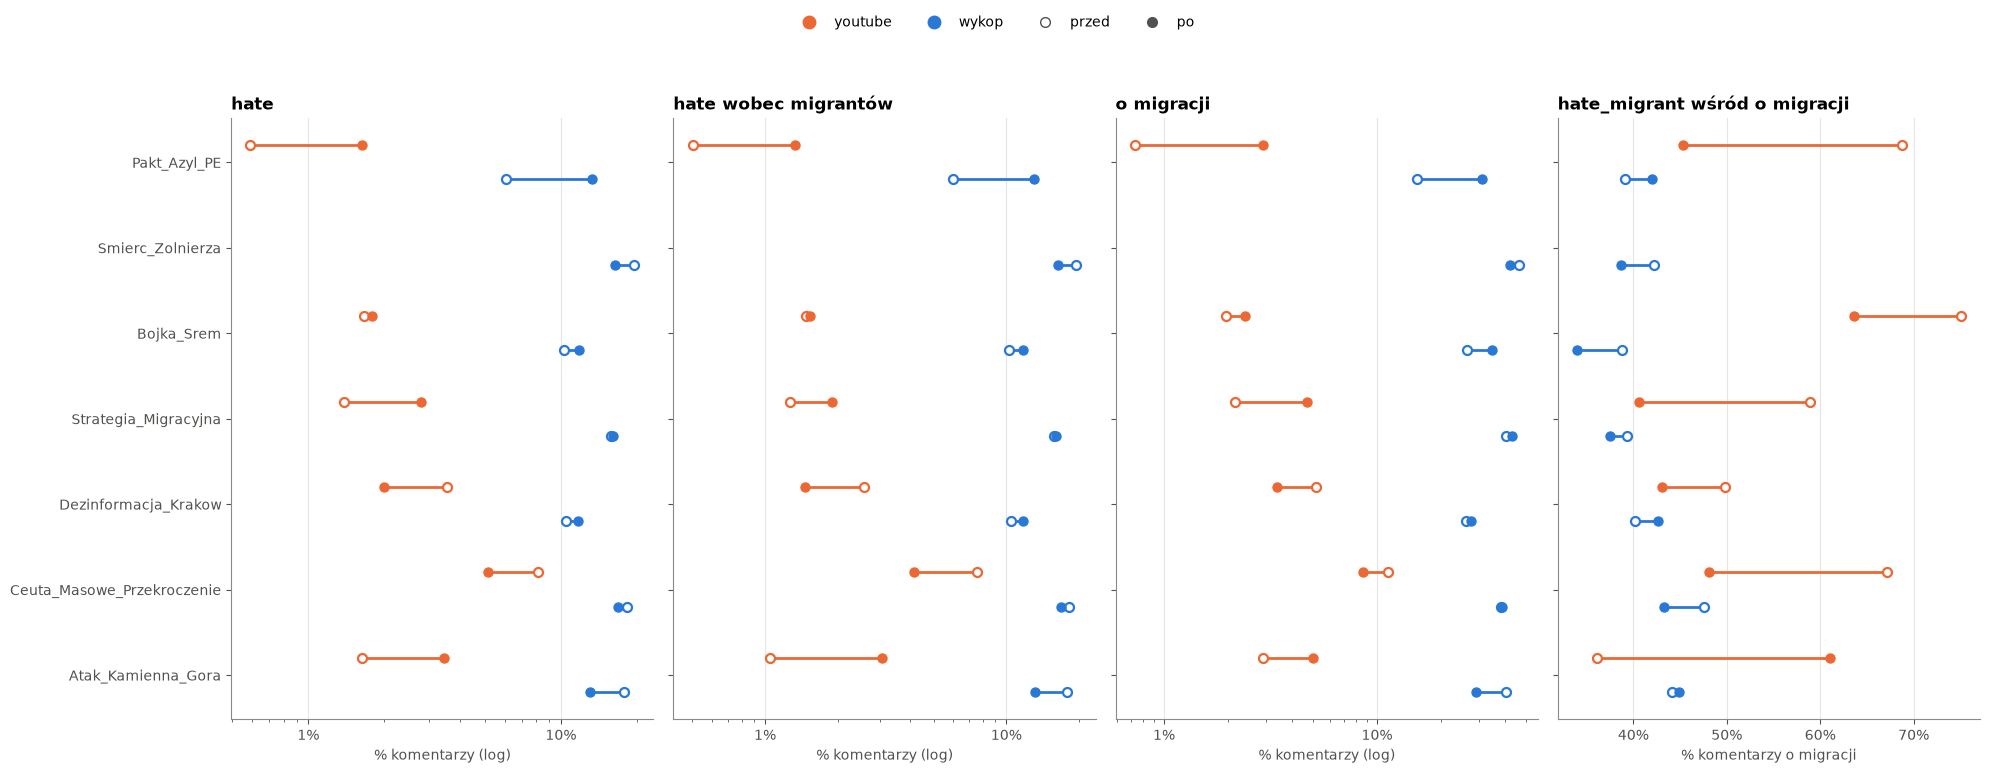

In [6]:
fig, axes = plt.subplots(1, len(LABEL_SETS), figsize=(20, 0.85 * len(EVENT_ORDER) + 1.8), sharey=True)
y = np.arange(len(EVENT_ORDER))
offs = np.linspace(-0.2, 0.2, len(PL)) if len(PL) > 1 else np.zeros(1)
for ax, name in zip(axes, LABEL_SETS):
    for off, p in zip(offs, PL):
        e = eff[(eff["etykieta"] == name) & (eff["platform"] == p)].set_index("event").reindex(EVENT_ORDER)
        e = e[e["przed %"].gt(0) & e["po %"].gt(0) & e["log OR"].notna()]
        yy = np.array([EVENT_ORDER.index(ev) for ev in e.index]) + off
        ax.hlines(yy, e["przed %"], e["po %"], color=PLATFORM_COLORS[p], lw=2)
        ax.scatter(e["przed %"], yy, s=42, facecolor="white", edgecolor=PLATFORM_COLORS[p], linewidth=1.6, zorder=3)
        ax.scatter(e["po %"], yy, s=42, color=PLATFORM_COLORS[p], zorder=3)
    conditional = LABEL_SETS[name][1] is not None  # odsetek wśród o migracji: wąski zakres, skala liniowa
    if not conditional:
        ax.set_xscale("log")
        ax.xaxis.set_minor_formatter(mticker.NullFormatter())
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}%"))
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True, which="major")
    ax.set_title(SHORT_NAMES[name])
    ax.set_xlabel("% komentarzy o migracji" if conditional else "% komentarzy (log)")
axes[0].set_yticks(y, EVENT_ORDER)
axes[0].invert_yaxis()
platform_legend(fig, extra=[(plt.Line2D([], [], marker="o", ls="", ms=7, mfc="white", mec=INK2), "przed"),
                            (plt.Line2D([], [], marker="o", ls="", ms=7, color=INK2), "po")])
plt.show()

## 2. Gdzie reakcja była silniejsza? To samo wydarzenie na różnych platformach

Dla każdego wydarzenia porównujemy OR między platformami:
- **ROR** (ratio of odds ratios) = OR platformy A / OR platformy B; ROR > 1 = po wydarzeniu na A wzrost (względny) był większy,
- **test Cochrana Q** różnicy OR między platformami (df = liczba platform − 1; przy 2 platformach to zwykły test z różnicy log OR),
- p korygowane Holmem w obrębie etykiety (bo testujemy wiele wydarzeń).

Porównujemy **względne** zmiany (OR), bo poziomy bazowe na platformach są bardzo różne.

In [7]:
def q_test(y, se):
    y, se = np.asarray(y, float), np.asarray(se, float)
    w = 1 / se ** 2
    mu = (w * y).sum() / w.sum()
    q = (w * (y - mu) ** 2).sum()
    return q, stats.chi2.sf(q, len(y) - 1)


cmp_rows = []
for name in LABEL_SETS:
    for ev in EVENT_ORDER:
        e = eff[(eff["etykieta"] == name) & (eff["event"] == ev)].dropna(subset=["log OR"]).set_index("platform")
        row = {"etykieta": name, "event": ev, "typ": EVENT_META[ev][0]}
        for p in PL:
            row[f"zmiana pp {p}"] = e["różnica pp"].get(p, np.nan)
            row[f"OR {p}"] = e["OR"].get(p, np.nan)
        if len(e) >= 2:
            row["p różnicy platform"] = q_test(e["log OR"], e["se"])[1]
            row["najsilniejszy wzrost"] = e["log OR"].idxmax()
            row["najsłabszy"] = e["log OR"].idxmin()
        for a, b in combinations(PL, 2):
            if a in e.index and b in e.index:
                d_, s_ = e.loc[a, "log OR"] - e.loc[b, "log OR"], np.hypot(e.loc[a, "se"], e.loc[b, "se"])
                row[f"ROR {a}/{b}"] = np.exp(d_)
                row[f"ROR lo {a}/{b}"], row[f"ROR hi {a}/{b}"] = np.exp(d_ - 1.96 * s_), np.exp(d_ + 1.96 * s_)
        cmp_rows.append(row)
cmp_ev = pd.DataFrame(cmp_rows)
if "p różnicy platform" in cmp_ev:
    cmp_ev["p (Holm)"] = cmp_ev.groupby("etykieta")["p różnicy platform"].transform(holm)
    cmp_ev["platformy różne"] = cmp_ev["p (Holm)"] < ALPHA
for name in LABEL_SETS:
    print(f"\n=== {LABEL_NAMES[name]} ===")
    display(fmt_p(cmp_ev[cmp_ev["etykieta"] == name].drop(columns="etykieta").set_index("event"), 2))


=== hate (w dyskusji o migracji) ===


,typ,zmiana pp youtube,OR youtube,zmiana pp wykop,OR wykop,p różnicy platform,najsilniejszy wzrost,najsłabszy,ROR youtube/wykop,ROR lo youtube/wykop,ROR hi youtube/wykop,p (Holm),platformy różne
event,,,,,,,,,,,,,
Pakt_Azyl_PE,polityka / prawo,1.05,2.81,7.16,2.36,0.619,youtube,wykop,1.19,0.60,2.36,1,False
Smierc_Zolnierza,przemoc / incydent,NaN,NaN,-3.17,0.81,,NaN,NaN,NaN,NaN,NaN,,False
Bojka_Srem,przemoc / incydent,0.13,1.08,1.47,1.16,0.83,wykop,youtube,0.93,0.47,1.82,1,False
Strategia_Migracyjna,polityka / prawo,1.42,2.06,0.27,1.02,0.0783,youtube,wykop,2.02,0.92,4.40,0.392,False
Dezinformacja_Krakow,dezinformacja,-1.55,0.55,1.25,1.13,0.11,wykop,youtube,0.49,0.20,1.18,0.441,False
Ceuta_Masowe_Przekroczenie,kryzys graniczny,-3.02,0.61,-1.43,0.91,0.356,wykop,youtube,0.67,0.29,1.56,1,False
Atak_Kamienna_Gora,przemoc / incydent,1.81,2.15,-4.70,0.70,0.00748,youtube,wykop,3.09,1.35,7.06,0.0449,True



=== hate wobec migrantów ===


,typ,zmiana pp youtube,OR youtube,zmiana pp wykop,OR wykop,p różnicy platform,najsilniejszy wzrost,najsłabszy,ROR youtube/wykop,ROR lo youtube/wykop,ROR hi youtube/wykop,p (Holm),platformy różne
event,,,,,,,,,,,,,
Pakt_Azyl_PE,polityka / prawo,0.83,2.67,7.04,2.35,0.703,youtube,wykop,1.14,0.58,2.22,1,False
Smierc_Zolnierza,przemoc / incydent,NaN,NaN,-3.17,0.81,,NaN,NaN,NaN,NaN,NaN,,False
Bojka_Srem,przemoc / incydent,0.06,1.04,1.46,1.16,0.749,wykop,youtube,0.90,0.46,1.76,1,False
Strategia_Migracyjna,polityka / prawo,0.63,1.50,0.27,1.02,0.346,youtube,wykop,1.47,0.66,3.31,1,False
Dezinformacja_Krakow,dezinformacja,-1.10,0.57,1.25,1.13,0.0846,wykop,youtube,0.50,0.23,1.10,0.423,False
Ceuta_Masowe_Przekroczenie,kryzys graniczny,-3.41,0.53,-1.43,0.91,0.209,wykop,youtube,0.59,0.25,1.35,0.837,False
Atak_Kamienna_Gora,przemoc / incydent,2.01,2.98,-4.70,0.70,0.000415,youtube,wykop,4.27,1.91,9.57,0.00249,True



=== o migracji ===


,typ,zmiana pp youtube,OR youtube,zmiana pp wykop,OR wykop,p różnicy platform,najsilniejszy wzrost,najsłabszy,ROR youtube/wykop,ROR lo youtube/wykop,ROR hi youtube/wykop,p (Holm),platformy różne
event,,,,,,,,,,,,,
Pakt_Azyl_PE,polityka / prawo,2.20,4.11,15.69,2.48,0.283,youtube,wykop,1.66,0.66,4.17,1,False
Smierc_Zolnierza,przemoc / incydent,NaN,NaN,-4.03,0.85,,NaN,NaN,NaN,NaN,NaN,,False
Bojka_Srem,przemoc / incydent,0.44,1.23,8.11,1.47,0.606,wykop,youtube,0.84,0.43,1.64,1,False
Strategia_Migracyjna,polityka / prawo,2.53,2.23,2.65,1.12,0.113,youtube,wykop,2.00,0.85,4.71,0.566,False
Dezinformacja_Krakow,dezinformacja,-1.74,0.65,1.44,1.08,0.329,wykop,youtube,0.60,0.22,1.66,1,False
Ceuta_Masowe_Przekroczenie,kryzys graniczny,-2.63,0.74,0.47,1.02,0.485,wykop,youtube,0.73,0.30,1.77,1,False
Atak_Kamienna_Gora,przemoc / incydent,2.11,1.76,-11.15,0.61,0.017,youtube,wykop,2.89,1.21,6.91,0.102,False



=== hate wobec migrantów wśród komentarzy o migracji ===


,typ,zmiana pp youtube,OR youtube,zmiana pp wykop,OR wykop,p różnicy platform,najsilniejszy wzrost,najsłabszy,ROR youtube/wykop,ROR lo youtube/wykop,ROR hi youtube/wykop,p (Holm),platformy różne
event,,,,,,,,,,,,,
Pakt_Azyl_PE,polityka / prawo,-23.41,0.38,2.92,1.13,0.00246,wykop,youtube,0.33,0.16,0.68,0.0148,True
Smierc_Zolnierza,przemoc / incydent,NaN,NaN,-3.46,0.87,,NaN,NaN,NaN,NaN,NaN,,False
Bojka_Srem,przemoc / incydent,-11.39,0.58,-4.87,0.81,0.346,wykop,youtube,0.72,0.36,1.43,0.692,False
Strategia_Migracyjna,polityka / prawo,-18.36,0.48,-1.81,0.93,0.00282,wykop,youtube,0.51,0.33,0.80,0.0148,True
Dezinformacja_Krakow,dezinformacja,-6.77,0.76,2.42,1.11,0.36,wykop,youtube,0.69,0.31,1.53,0.692,False
Ceuta_Masowe_Przekroczenie,kryzys graniczny,-19.03,0.45,-4.28,0.84,0.0976,wykop,youtube,0.54,0.26,1.12,0.293,False
Atak_Kamienna_Gora,przemoc / incydent,24.98,2.78,0.77,1.03,0.00526,youtube,wykop,2.69,1.34,5.40,0.021,True


### Wykres lasu: OR każdego wydarzenia na każdej platformie

Kropka = OR (po vs przed), kreska = 95% CI, kolor = platforma. Romby na dole = **łączny OR platformy z metaanalizy**
efektów losowych (szczegóły w sekcji 3). Linia OR = 1 = brak zmiany.

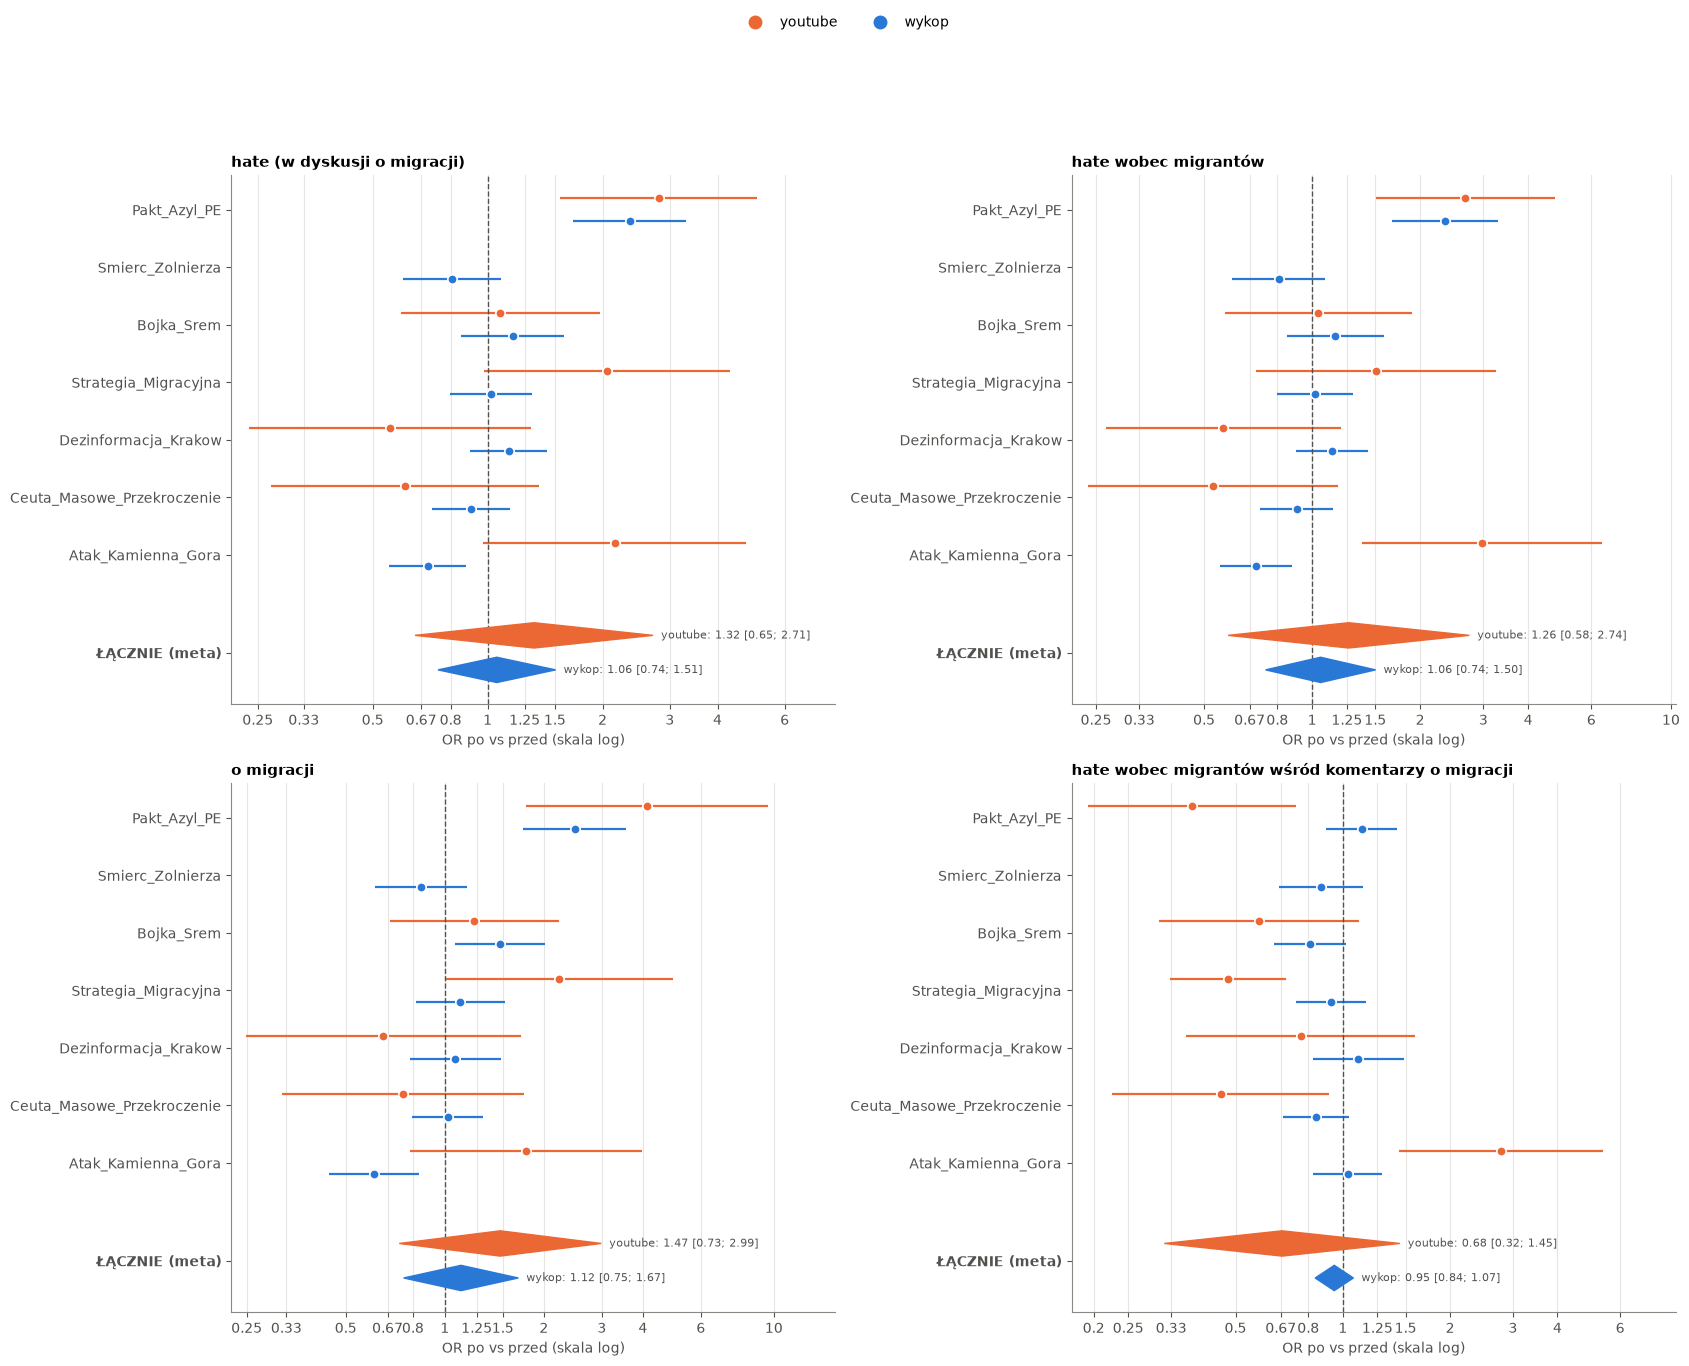

In [8]:
def meta_random(y, se):
    """Metaanaliza efektów losowych: DerSimonian–Laird + przedział Hartung–Knapp (t, k-1 df)."""
    y, se = np.asarray(y, float), np.asarray(se, float)
    ok = ~(np.isnan(y) | np.isnan(se))
    y, se = y[ok], se[ok]
    k = len(y)
    if k == 0:
        return {"k": 0, "mu": np.nan, "se": np.nan, "lo": np.nan, "hi": np.nan, "p": np.nan, "tau2": np.nan,
                "I2": np.nan, "p Q": np.nan}
    w = 1 / se ** 2
    fixed = (w * y).sum() / w.sum()
    q = (w * (y - fixed) ** 2).sum()
    c = w.sum() - (w ** 2).sum() / w.sum()
    tau2 = max(0.0, (q - (k - 1)) / c) if k > 1 else 0.0
    ws = 1 / (se ** 2 + tau2)
    mu = (ws * y).sum() / ws.sum()
    if k == 1:
        return {"k": 1, "mu": mu, "se": se[0], "lo": mu - 1.96 * se[0], "hi": mu + 1.96 * se[0],
                "p": 2 * stats.norm.sf(abs(mu / se[0])), "tau2": 0.0, "I2": np.nan, "p Q": np.nan}
    se_hk = max(np.sqrt((ws * (y - mu) ** 2).sum() / ((k - 1) * ws.sum())), np.sqrt(1 / ws.sum()))
    t = stats.t.ppf(1 - ALPHA / 2, k - 1)
    return {"k": k, "mu": mu, "se": se_hk, "lo": mu - t * se_hk, "hi": mu + t * se_hk,
            "p": 2 * stats.t.sf(abs(mu / se_hk), k - 1),
            "tau2": tau2, "I2": max(0.0, (q - (k - 1)) / q) if q > 0 else 0.0, "p Q": stats.chi2.sf(q, k - 1)}


meta = {(name, p): meta_random(*eff.loc[(eff["etykieta"] == name) & (eff["platform"] == p), ["log OR", "se"]].T.values)
        for name in LABEL_SETS for p in PL}

fig, axes = plt.subplots(2, 2, figsize=(17, 2 * (0.62 * len(EVENT_ORDER) + 0.45 * len(PL) + 1.6)))
for ax, name in zip(axes.flat, LABEL_SETS):
    n_ev = len(EVENT_ORDER)
    base = np.arange(n_ev)[::-1] * 1.0 + 0.6 * len(PL) + 0.8
    for off, p in zip(offs, PL):
        e = eff[(eff["etykieta"] == name) & (eff["platform"] == p)].set_index("event").reindex(EVENT_ORDER)
        yy = base - off
        ax.hlines(yy, e["OR lo"], e["OR hi"], color=PLATFORM_COLORS[p], lw=1.6)
        ax.scatter(e["OR"], yy, s=46, color=PLATFORM_COLORS[p], edgecolor="white", linewidth=1.2, zorder=3)
    xs = [eff.loc[eff["etykieta"] == name, "OR lo"].min(), eff.loc[eff["etykieta"] == name, "OR hi"].max()]
    for i, p in enumerate(PL):
        m = meta[(name, p)]
        if m["k"] == 0:
            continue
        yd = 0.6 * (len(PL) - 1 - i)
        lo_, mu_, hi_ = np.exp([m["lo"], m["mu"], m["hi"]])
        ax.fill([lo_, mu_, hi_, mu_], [yd, yd + 0.22, yd, yd - 0.22], color=PLATFORM_COLORS[p], zorder=3)
        ax.text(hi_, yd, f"  {p}: {mu_:.2f} [{lo_:.2f}; {hi_:.2f}]", va="center", fontsize=8, color=INK2)
        xs += [lo_, hi_]
    ax.axvline(1, color=INK2, ls="--", lw=1)
    ax.set_xscale("log")
    xmin, xmax = np.nanmin(xs) * 0.9, np.nanmax(xs) * 1.6
    ax.set_xlim(xmin, xmax)
    ticks = [t for t in [0.1, 0.2, 0.25, 0.33, 0.5, 0.67, 0.8, 1, 1.25, 1.5, 2, 3, 4, 6, 10] if xmin <= t <= xmax]
    ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
    ax.xaxis.set_minor_locator(mticker.NullLocator())
    ax.set_yticks([*base, 0.3 * (len(PL) - 1)], [*EVENT_ORDER, "ŁĄCZNIE (meta)"])
    ax.get_yticklabels()[-1].set_fontweight("bold")
    ax.set_ylim(-0.6, base.max() + 0.6)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_xlabel("OR po vs przed (skala log)")
    ax.set_title(LABEL_NAMES[name], fontsize=11)
platform_legend(fig)
plt.show()

### Czy wydarzenia działają podobnie na różnych platformach?

Każdy punkt to wydarzenie: oś X = zmiana na jednej platformie, oś Y = na drugiej (pp). Punkty blisko przekątnej =
podobna reakcja; w ćwiartkach I/III = ten sam kierunek. Spearman ρ mówi, czy wydarzenia, które mocniej ruszyły jedną
platformę, mocniej ruszyły też drugą (przy kilku wydarzeniach – orientacyjnie).

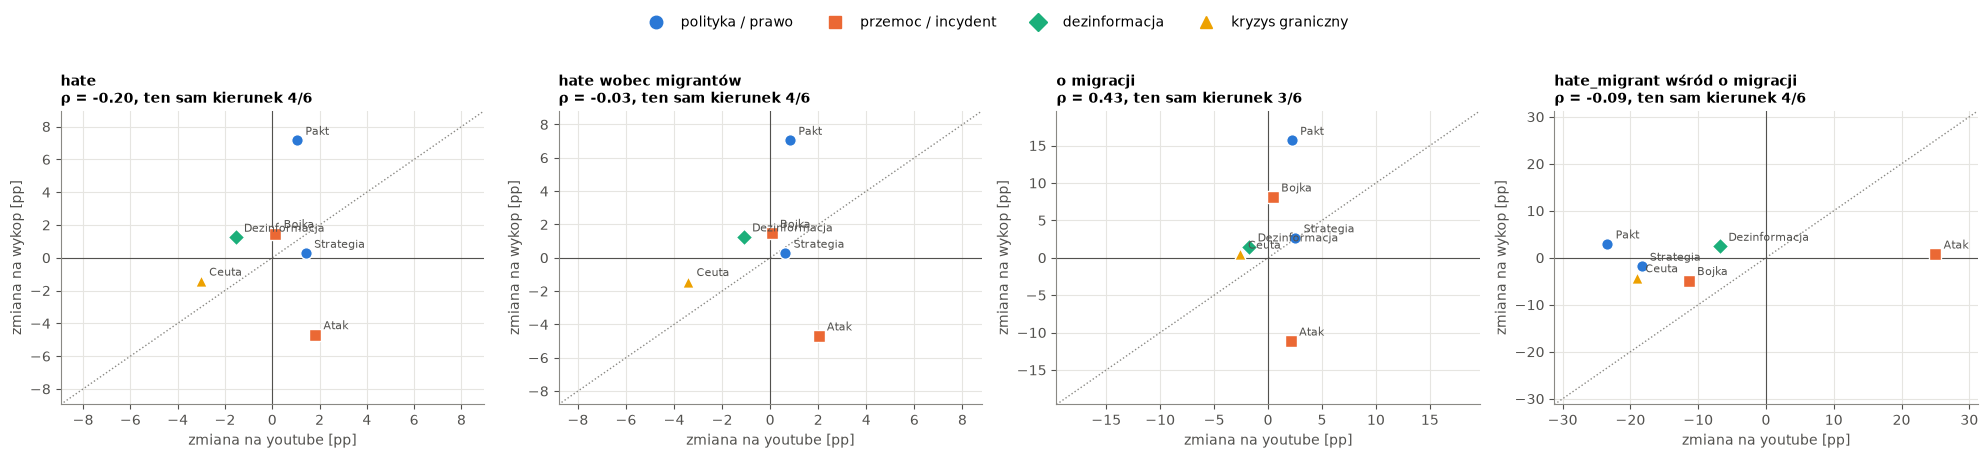

,,wydarzeń,ten sam kierunek,Spearman rho,p
etykieta,para,,,,
hate,youtube vs wykop,6,4/6,-0.200,0.704
hate_migrant,youtube vs wykop,6,4/6,-0.029,0.957
migrant,youtube vs wykop,6,3/6,0.429,0.397
hate_migrant | migrant,youtube vs wykop,6,4/6,-0.086,0.872


In [9]:
pairs = list(combinations(PL, 2))
corr_rows = []
if pairs:
    fig, axes = plt.subplots(len(pairs), len(LABEL_SETS), figsize=(20, 4.6 * len(pairs)), squeeze=False)
    for r, (a, b) in enumerate(pairs):
        for ax, name in zip(axes[r], LABEL_SETS):
            e = eff[eff["etykieta"] == name].pivot(index="event", columns="platform", values="różnica pp")
            e = e.reindex(EVENT_ORDER)[[a, b]].dropna()
            for ev, (xa, yb) in e.iterrows():
                t = EVENT_META[ev][0]
                ax.scatter(xa, yb, s=70, color=TYPE_COLORS[t], marker=TYPE_MARKERS[t], edgecolor="white", zorder=3)
                ax.annotate(ev.split("_")[0], (xa, yb), xytext=(6, 4), textcoords="offset points", fontsize=8, color=INK2)
            lim = np.abs(e.values).max() * 1.25 if len(e) else 1
            ax.plot([-lim, lim], [-lim, lim], color=MUTED, ls=":", lw=1)
            ax.axhline(0, color=INK2, lw=0.8)
            ax.axvline(0, color=INK2, lw=0.8)
            ax.set_xlim(-lim, lim)
            ax.set_ylim(-lim, lim)
            ax.grid(axis="x", visible=True)
            ax.set_xlabel(f"zmiana na {a} [pp]")
            ax.set_ylabel(f"zmiana na {b} [pp]")
            rho, p = stats.spearmanr(e[a], e[b]) if len(e) > 2 else (np.nan, np.nan)
            same = int((np.sign(e[a]) == np.sign(e[b])).sum())
            corr_rows.append({"etykieta": name, "para": f"{a} vs {b}", "wydarzeń": len(e),
                              "ten sam kierunek": f"{same}/{len(e)}", "Spearman rho": rho, "p": p})
            ax.set_title(f"{SHORT_NAMES[name]}\nρ = {rho:.2f}, ten sam kierunek {same}/{len(e)}", fontsize=10)
    type_legend(fig)
    plt.show()
    display(fmt_p(pd.DataFrame(corr_rows).set_index(["etykieta", "para"]), 3))

## 3. Test H4: czy efekt wydarzeń różni się między platformami?

Trzy uzupełniające się podejścia:

1. **Metaanaliza osobno dla każdej platformy** (efekty losowe, DerSimonian–Laird + Hartung–Knapp, jak w notebooku Wykopu)
   → łączny OR platformy i **test różnicy podgrup** (Q między platformami).
2. **Porównanie sparowane po wydarzeniu** – to *ta sama* lista wydarzeń na każdej platformie, więc dla każdego wydarzenia
   liczymy różnicę log OR (A − B) i metaanalizujemy te różnice → **łączny ROR**. To główny test H4: odpowiada na pytanie
   „czy przy tym samym wydarzeniu jedna platforma reaguje systematycznie silniej”. Uzupełnia go **test Wilcoxona**
   (sparowany, nieparametryczny) na zmianach w pp.
3. **Jeden model na wszystkich komentarzach**: `y ~ C(platforma:wydarzenie) + po + po:C(platform)` (klastry po wątku);
   test Walda członu `po:C(platform)` = czy średni efekt „po” różni się między platformami.

In [10]:
plat_rows = []
for name in LABEL_SETS:
    for p in PL:
        m, e = meta[(name, p)], eff[(eff["etykieta"] == name) & (eff["platform"] == p)].dropna(subset=["log OR"])
        n_up = int((e["różnica pp"] > 0).sum())
        plat_rows.append({"etykieta": name, "platform": p, "wydarzeń": m["k"], "wzrost w": f"{n_up}/{len(e)}",
                          "istotny wzrost w": f"{int((e['istotne'] & (e['różnica pp'] > 0)).sum())}/{len(e)}",
                          "średnia zmiana pp": e["różnica pp"].mean(),
                          "OR łączny": np.exp(m["mu"]), "OR lo": np.exp(m["lo"]), "OR hi": np.exp(m["hi"]),
                          "p meta": m["p"], "I²": m["I2"], "mu": m["mu"], "se_mu": m["se"]})
plat = pd.DataFrame(plat_rows)
plat["p meta (Holm)"] = plat.groupby("platform")["p meta"].transform(holm)

sub_rows = []
for name in LABEL_SETS:
    g = plat[(plat["etykieta"] == name)].dropna(subset=["mu"])
    if len(g) >= 2:
        q, p = q_test(g["mu"], g["se_mu"])
        sub_rows.append({"etykieta": name, "Q między platformami": q, "df": len(g) - 1, "p różnicy podgrup": p})
print("Łączny efekt wydarzeń na każdej platformie (metaanaliza):")
display(fmt_p(plat.drop(columns=["mu", "se_mu"]).set_index(["etykieta", "platform"]), 3))
if sub_rows:
    print("Test różnicy podgrup (czy łączne OR platform się różnią):")
    display(fmt_p(pd.DataFrame(sub_rows).set_index("etykieta"), 3))

Łączny efekt wydarzeń na każdej platformie (metaanaliza):


wydarzeń wzrost w istotny wzrost w  średnia zmiana pp  OR łączny  OR lo  OR hi p meta     I² p meta (Holm)
etykieta               platform                                                                                                            
hate                   youtube          6      4/6              1/6             -0.027      1.323  0.645  2.712  0.362  0.702         0.869
                       wykop            7      4/7              1/7              0.122      1.057  0.741  1.507  0.716  0.844             1
hate_migrant           youtube          6      4/6              2/6             -0.163      1.265  0.583  2.743  0.471  0.756         0.869
                       wykop            7      4/7              1/7              0.104      1.056  0.742  1.503  0.719  0.843             1
migrant                youtube          6      4/6              1/6              0.485      1.474  0.727  2.989  0.217  0.599         0.869
                       wykop            7      5/7              1/7              1.884      1.120  0.750  1.673  0.516  0.846             1
hate_migrant | migrant youtube          6      1/6              1/6             -8.996      0.675  0.316  1.445  0.242  0.800         0.869
                       wykop            7      3/7              0/7             -1.186      0.946  0.836  1.071  0.317  0.177             1

Test różnicy podgrup (czy łączne OR platform się różnią):


,Q między platformami,df,p różnicy podgrup
etykieta,,,
hate,0.509,1,0.476
hate_migrant,0.292,1,0.589
migrant,0.737,1,0.391
hate_migrant | migrant,1.263,1,0.261


In [11]:
paired_rows = []
for name in LABEL_SETS:
    w = eff[eff["etykieta"] == name].pivot(index="event", columns="platform", values=["log OR", "se", "różnica pp"])
    for a, b in pairs:
        cols = [("log OR", a), ("log OR", b)]
        x = w.dropna(subset=cols)
        if len(x) == 0:
            continue
        d_ = x[("log OR", a)] - x[("log OR", b)]
        s_ = np.hypot(x[("se", a)], x[("se", b)])
        m = meta_random(d_, s_)
        dpp = x[("różnica pp", a)] - x[("różnica pp", b)]
        wil = stats.wilcoxon(x[("różnica pp", a)], x[("różnica pp", b)]) if len(x) >= 5 else None
        paired_rows.append({
            "etykieta": name, "para (A vs B)": f"{a} vs {b}", "wydarzeń": len(x),
            "silniej na A w": f"{int((d_ > 0).sum())}/{len(x)}",
            "ROR łączny (A/B)": np.exp(m["mu"]), "ROR lo": np.exp(m["lo"]), "ROR hi": np.exp(m["hi"]),
            "p meta": m["p"], "I² różnic": m["I2"],
            "średnia różnica zmian pp (A−B)": dpp.mean(),
            "p Wilcoxon (pp)": wil.pvalue if wil is not None else np.nan})
paired = pd.DataFrame(paired_rows)
if len(paired):
    paired["p meta (Holm)"] = holm(paired["p meta"])
    print("Porównanie sparowane po wydarzeniu (ROR > 1 = po wydarzeniach względny wzrost silniejszy na A):")
    display(fmt_p(paired.set_index(["etykieta", "para (A vs B)"]), 3))

Porównanie sparowane po wydarzeniu (ROR > 1 = po wydarzeniach względny wzrost silniejszy na A):


,,wydarzeń,silniej na A w,ROR łączny (A/B),ROR lo,ROR hi,p meta,I² różnic,średnia różnica zmian pp (A−B),p Wilcoxon (pp),p meta (Holm)
etykieta,para (A vs B),,,,,,,,,,
hate,youtube vs wykop,6,3/6,1.155,0.573,2.329,0.62,0.617,-0.697,0.562,1
hate_migrant,youtube vs wykop,6,3/6,1.108,0.498,2.465,0.755,0.719,-0.812,0.562,1
migrant,youtube vs wykop,6,3/6,1.235,0.645,2.365,0.441,0.491,-2.385,0.312,1
hate_migrant | migrant,youtube vs wykop,6,1/6,0.701,0.333,1.472,0.273,0.760,-8.190,0.312,1


In [12]:
def wald(d, col, formula, keep):
    """Test Walda dla współczynników, których nazwy spełniają keep(name); regresja logistyczna z klastrami po wątku."""
    try:
        m = smf.logit(formula, data=d.assign(y=d[col].astype(int))).fit(
            disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(d["thread"])[0]}, maxiter=200)
    except Exception as ex:
        print("  model nie zbiegł:", str(ex)[:100])
        return np.nan, None
    idx = [i for i, n in enumerate(m.params.index) if keep(n)]
    if not idx:
        return np.nan, m
    return float(m.wald_test(np.eye(len(m.params))[idx], scalar=True).pvalue), m


model_rows = []
if len(PL) >= 2:
    for name, (col, cond) in LABEL_SETS.items():
        d = all_df[all_df[cond]] if cond else all_df
        p, m = wald(d, col, "y ~ C(pe) + po + po:C(platform)", lambda n: n.startswith("po:C(platform)"))
        row = {"etykieta": name, "p (po × platforma)": p}
        if m is not None:
            # poziom odniesienia patsy = pierwsza platforma alfabetycznie, jej interakcja = 0
            for q in PL:
                row[f"OR po {q}"] = np.exp(m.params["po"] + m.params.get(f"po:C(platform)[T.{q}]", 0.0))
        model_rows.append(row)
    model_h4 = pd.DataFrame(model_rows).set_index("etykieta")
    model_h4["p (Holm)"] = holm(model_h4["p (po × platforma)"]).values
    display(fmt_p(model_h4, 3))

,p (po × platforma),OR po youtube,OR po wykop,p (Holm)
etykieta,,,,
hate,0.805,1.084,1.028,1
hate_migrant,0.926,1.005,1.026,1
migrant,0.621,1.248,1.118,1
hate_migrant | migrant,0.0431,0.628,0.930,0.172


### 3b. Poziom hejtu między platformami (test z README: Kruskal–Wallis → Dunn + Holm)

Jednostka = **dzień** danego wydarzenia na danej platformie (dni z ≥ `MIN_DAILY_N` komentarzami w mianowniku).
Porównujemy dzienne odsetki między platformami osobno dla okresu przed i po. Dni z jednego wydarzenia nie są w pełni
niezależne, więc p-value traktuj orientacyjnie; **wielkość różnicy (mediany)** jest tu ważniejsza.
Przypomnienie: dla `hate`, `hate_migrant` i `migrant` różnica poziomu odzwierciedla też to, ile treści nie-migracyjnych
jest na platformie – najbardziej porównywalny jest wiersz `hate_migrant | migrant`.

In [13]:
def dunn(values, groups):
    """Test Dunna (po Kruskalu–Wallisie) z poprawką na wiązania; zwraca p (Holm) dla par grup."""
    v, g = np.asarray(values, float), np.asarray(groups)
    r = stats.rankdata(v)
    n = len(v)
    _, t = np.unique(v, return_counts=True)
    s2 = n * (n + 1) / 12 - (t ** 3 - t).sum() / (12 * (n - 1))
    rows = []
    for a, b in combinations(pd.unique(g), 2):
        ra, rb, na, nb = r[g == a].mean(), r[g == b].mean(), (g == a).sum(), (g == b).sum()
        z = (ra - rb) / np.sqrt(s2 * (1 / na + 1 / nb))
        rows.append({"para": f"{a} vs {b}", "z": z, "p": 2 * stats.norm.sf(abs(z))})
    out = pd.DataFrame(rows)
    out["p (Holm)"] = holm(out["p"]).values
    return out


daily = (all_df.groupby(["platform", "event", "relative_day", "okres"])
         .agg(n=("comment_id", "size"), migrant=("migrant", "sum"), hate=("hate", "sum"),
              hate_migrant=("hate_migrant", "sum")).reset_index())

kw_rows, dunn_rows = [], []
for name, (col, cond) in LABEL_SETS.items():
    den = cond or "n"
    dd = daily[daily[den] >= MIN_DAILY_N].assign(share=lambda x: 100 * x[col] / x[den])
    for okres in ["przed", "po"]:
        g = dd[dd["okres"] == okres]
        groups = [g.loc[g["platform"] == p, "share"].values for p in PL if (g["platform"] == p).sum() > 0]
        row = {"etykieta": name, "okres": okres,
               **{f"mediana {p} [%]": g.loc[g["platform"] == p, "share"].median() for p in PL},
               **{f"dni {p}": int((g["platform"] == p).sum()) for p in PL}}
        if len(groups) >= 2:
            row["p Kruskal–Wallis"] = stats.kruskal(*groups).pvalue
            for _, r in dunn(g["share"], g["platform"]).iterrows():
                dunn_rows.append({"etykieta": name, "okres": okres, "para": r["para"], "z": r["z"], "p (Holm)": r["p (Holm)"]})
        kw_rows.append(row)
display(fmt_p(pd.DataFrame(kw_rows).set_index(["etykieta", "okres"]), 2))
if dunn_rows:
    print("Post-hoc Dunn (Holm):")
    display(fmt_p(pd.DataFrame(dunn_rows).set_index(["etykieta", "okres", "para"]), 3))

mediana youtube [%]  mediana wykop [%]  dni youtube  dni wykop p Kruskal–Wallis
etykieta               okres                                                                                 
hate                   przed                 1.63              14.75           42         47         1.16e-13
                       po                    2.07              13.86          114        133         1.96e-40
hate_migrant           przed                 1.37              14.75           42         47         2.91e-14
                       po                    1.70              13.86          114        133         3.39e-41
migrant                przed                 2.12              34.84           42         47         2.18e-15
                       po                    3.14              35.32          114        133         4.31e-41
hate_migrant | migrant przed                62.32              42.06           42         47         1.03e-07
                       po                   54.12              41.50          108        133         5.39e-14

Post-hoc Dunn (Holm):


z  p (Holm)
etykieta               okres para                              
hate                   przed wykop vs youtube   7.421  1.16e-13
                       po    wykop vs youtube  13.313  1.96e-40
hate_migrant           przed wykop vs youtube   7.602  2.91e-14
                       po    wykop vs youtube  13.443  3.39e-41
migrant                przed wykop vs youtube   7.931  2.18e-15
                       po    wykop vs youtube  13.425  4.31e-41
hate_migrant | migrant przed wykop vs youtube  -5.322  1.03e-07
                       po    wykop vs youtube  -7.522  5.39e-14

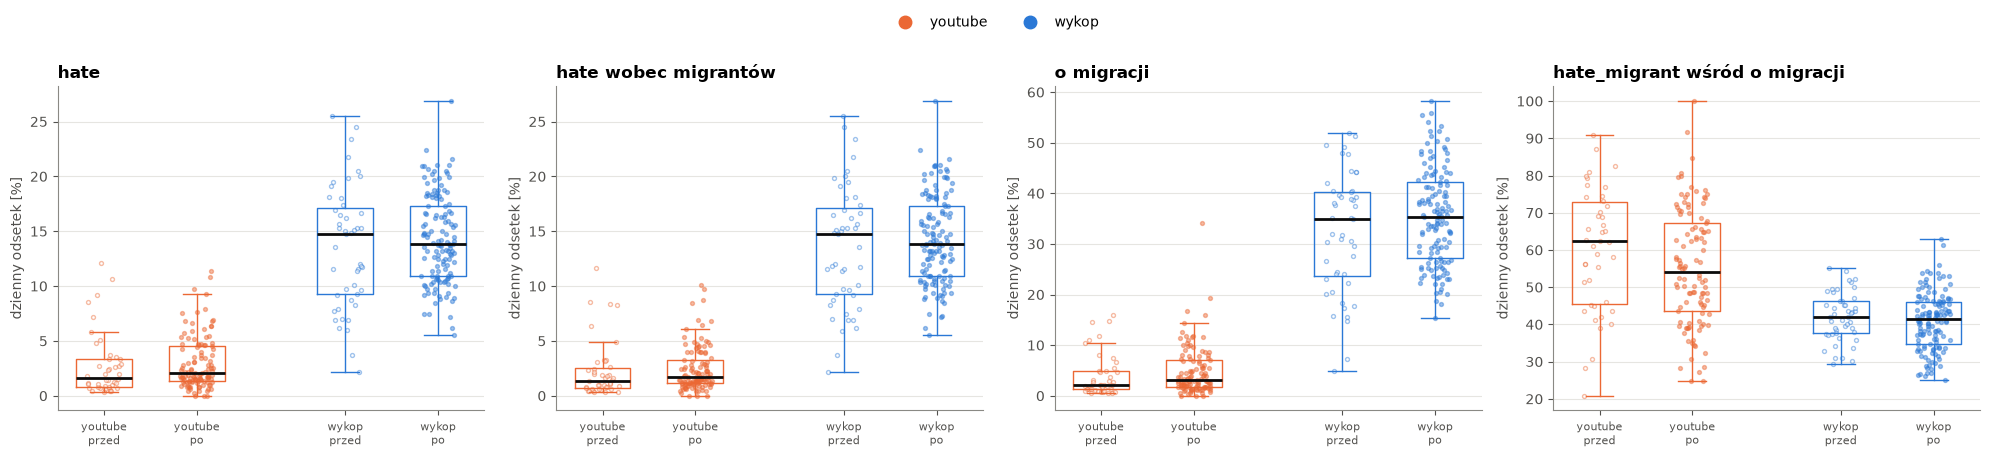

In [14]:
fig, axes = plt.subplots(1, len(LABEL_SETS), figsize=(20, 4.6))
rs = np.random.default_rng(0)
for ax, (name, (col, cond)) in zip(axes, LABEL_SETS.items()):
    den = cond or "n"
    dd = daily[daily[den] >= MIN_DAILY_N].assign(share=lambda x: 100 * x[col] / x[den])
    pos = 0
    ticks, labels = [], []
    for p in PL:
        for okres in ["przed", "po"]:
            v = dd.loc[(dd["platform"] == p) & (dd["okres"] == okres), "share"]
            if len(v):
                ax.boxplot(v, positions=[pos], widths=0.6, showfliers=False, medianprops={"color": INK, "lw": 2},
                           boxprops={"color": PLATFORM_COLORS[p]}, whiskerprops={"color": PLATFORM_COLORS[p]},
                           capprops={"color": PLATFORM_COLORS[p]})
                ax.scatter(pos + rs.uniform(-0.18, 0.18, len(v)), v, s=8, alpha=0.45, color=PLATFORM_COLORS[p],
                           facecolor="white" if okres == "przed" else PLATFORM_COLORS[p])
            ticks.append(pos)
            labels.append(f"{p}\n{okres}")
            pos += 1
        pos += 0.6
    ax.set_xticks(ticks, labels, fontsize=8)
    ax.set_ylabel("dzienny odsetek [%]")
    ax.set_title(SHORT_NAMES[name])
platform_legend(fig)
plt.show()

### 3c. Analiza wrażliwości: krótkie, symetryczne okna bez nakładania

Ceuta i Kamienna Góra (16 dni różnicy) oraz Śrem i Strategia (34 dni) mają nakładające się okna – „przed” późniejszego
wydarzenia zawiera „po” wcześniejszego. Tu każde wydarzenie dostaje symetryczne okno ±W dni, gdzie W nie przekracza
wspólnego okna platform i połowy odstępu do najbliższego wydarzenia. Jeśli wnioski H4 są podobne – są odporne na
nakładanie się okien.

In [15]:
dates = {e: pd.Timestamp(EVENTS[e]) for e in EVENT_ORDER}
TRIM = {e: int(min(-WINDOW.loc[e, "od"], WINDOW.loc[e, "do"],
                   min([(abs((dates[e] - dates[o]).days) - 1) // 2 for o in EVENT_ORDER if o != e], default=99)))
        for e in EVENT_ORDER}
print("okno symetryczne bez nakładania (± dni):", TRIM)
trim_df = all_df[all_df["relative_day"].abs() <= all_df["event"].map(TRIM)]
eff_trim = effects(trim_df)

sens_rows = []
for name in LABEL_SETS:
    for p in PL:
        m = meta_random(*eff_trim.loc[(eff_trim["etykieta"] == name) & (eff_trim["platform"] == p), ["log OR", "se"]].T.values)
        sens_rows.append({"etykieta": name, "porównanie": p, "OR (okno wspólne)": plat.set_index(["etykieta", "platform"]).loc[(name, p), "OR łączny"],
                          "OR (bez nakładania)": np.exp(m["mu"]), "lo": np.exp(m["lo"]), "hi": np.exp(m["hi"]), "p": m["p"]})
    w = eff_trim[eff_trim["etykieta"] == name].pivot(index="event", columns="platform", values=["log OR", "se"])
    for a, b in pairs:
        x = w.dropna(subset=[("log OR", a), ("log OR", b)])
        m = meta_random(x[("log OR", a)] - x[("log OR", b)], np.hypot(x[("se", a)], x[("se", b)]))
        pr = paired.set_index(["etykieta", "para (A vs B)"])
        sens_rows.append({"etykieta": name, "porównanie": f"ROR {a}/{b}",
                          "OR (okno wspólne)": pr.loc[(name, f"{a} vs {b}"), "ROR łączny (A/B)"],
                          "OR (bez nakładania)": np.exp(m["mu"]), "lo": np.exp(m["lo"]), "hi": np.exp(m["hi"]), "p": m["p"]})
display(fmt_p(pd.DataFrame(sens_rows).set_index(["etykieta", "porównanie"]), 3))

okno symetryczne bez nakładania (± dni): {'Pakt_Azyl_PE': 7, 'Smierc_Zolnierza': 5, 'Bojka_Srem': 7, 'Strategia_Migracyjna': 7, 'Dezinformacja_Krakow': 7, 'Ceuta_Masowe_Przekroczenie': 7, 'Atak_Kamienna_Gora': 7}


OR (okno wspólne)  OR (bez nakładania)     lo     hi      p
etykieta               porównanie                                                                    
hate                   youtube                        1.323                1.145  0.430  3.051  0.736
                       wykop                          1.057                0.960  0.668  1.380  0.793
                       ROR youtube/wykop              1.155                1.139  0.465  2.791  0.723
hate_migrant           youtube                        1.265                1.102  0.437  2.779  0.798
                       wykop                          1.056                0.959  0.669  1.374  0.784
                       ROR youtube/wykop              1.108                1.099  0.481  2.513   0.78
migrant                youtube                        1.474                1.330  0.461  3.834   0.52
                       wykop                          1.120                1.045  0.715  1.526  0.787
                       ROR youtube/wykop              1.235                1.211  0.472  3.112  0.624
hate_migrant | migrant youtube                        0.675                0.612  0.291  1.290  0.152
                       wykop                          0.946                0.901  0.734  1.106  0.261
                       ROR youtube/wykop              0.701                0.683  0.343  1.361  0.215

## 4. Typ wydarzenia × platforma

- **Tabela**: średnia zmiana (pp), łączny OR (metaanaliza) i średni poziom po wydarzeniu dla każdego typu na każdej platformie.
- **Czy typ różnicuje efekt na danej platformie?** – model `y ~ C(event) + po + po:C(typ)` osobno dla platformy, test `po:C(typ)`.
- **Czy typ działa różnie na różnych platformach?** – model na wszystkich danych
  `y ~ C(pe) + po + po:C(platform) + po:C(typ) + po:C(typ):C(platform)`, test potrójnej interakcji.

⚠️ W każdym typie jest 1–3 wydarzeń, więc „typ” prawie pokrywa się z konkretnym wydarzeniem – traktuj opisowo.

In [16]:
type_rows = []
for name in LABEL_SETS:
    for p in PL:
        for grp in ["typ", "zasieg"]:
            for g, e in eff[(eff["etykieta"] == name) & (eff["platform"] == p)].groupby(grp, sort=False):
                m = meta_random(e["log OR"], e["se"])
                type_rows.append({"etykieta": name, "podział": grp, "grupa": g, "platform": p,
                                  "wydarzeń": len(e), "poziom po [%]": e["po %"].mean(),
                                  "średnia zmiana pp": e["różnica pp"].mean(), "OR łączny": np.exp(m["mu"]),
                                  "OR lo": np.exp(m["lo"]), "OR hi": np.exp(m["hi"])})
by_type = pd.DataFrame(type_rows)
for name in LABEL_SETS:
    print(f"\n=== {LABEL_NAMES[name]} ===")
    t = by_type[by_type["etykieta"] == name].pivot(index=["podział", "grupa"], columns="platform",
                                                    values=["poziom po [%]", "średnia zmiana pp", "OR łączny"])
    display(t.reindex(columns=PL, level=1).round(2))

test_rows = []
for name, (col, cond) in LABEL_SETS.items():
    row = {"etykieta": name}
    for p in PL:
        d = all_df[(all_df["platform"] == p) & (all_df[cond] if cond else True)]
        row[f"p typ [{p}]"] = wald(d, col, "y ~ C(event) + po + po:C(typ)", lambda n: n.startswith("po:C(typ)"))[0]
        row[f"p zasięg [{p}]"] = wald(d, col, "y ~ C(event) + po + po:C(zasieg)", lambda n: n.startswith("po:C(zasieg)"))[0]
    if len(PL) >= 2:
        d = all_df[all_df[cond]] if cond else all_df
        row["p typ × platforma"] = wald(d, col, "y ~ C(pe) + po + po:C(platform) + po:C(typ) + po:C(typ):C(platform)",
                                        lambda n: n.startswith("po:C(typ)") and ":C(platform)" in n)[0]
    test_rows.append(row)
display(fmt_p(pd.DataFrame(test_rows).set_index("etykieta"), 3))


=== hate (w dyskusji o migracji) ===


poziom po [%]        średnia zmiana pp       OR łączny      
platform                         youtube  wykop           youtube wykop   youtube wykop
podział grupa                                                                          
typ     dezinformacja               1.99  11.74             -1.55  1.25      0.55  1.13
        kryzys graniczny            5.12  16.78             -3.02 -1.43      0.61  0.91
        polityka / prawo            2.22  14.65              1.23  3.71      2.49  1.54
        przemoc / incydent          2.61  13.74              0.97 -2.13      1.45  0.86
zasieg  Polska                      2.51  13.81              0.45 -0.97      1.29  0.94
        UE / zagranica              3.38  15.01             -0.99  2.86      1.34  1.45


=== hate wobec migrantów ===


poziom po [%]        średnia zmiana pp       OR łączny      
platform                         youtube  wykop           youtube wykop   youtube wykop
podział grupa                                                                          
typ     dezinformacja               1.47  11.74             -1.10  1.25      0.57  1.13
        kryzys graniczny            4.16  16.78             -3.41 -1.43      0.53  0.91
        polityka / prawo            1.61  14.56              0.73  3.66      2.13  1.53
        przemoc / incydent          2.30  13.74              1.04 -2.13      1.71  0.86
zasieg  Polska                      1.99  13.80              0.40 -0.98      1.26  0.94
        UE / zagranica              2.74  14.92             -1.29  2.81      1.22  1.45


=== o migracji ===


poziom po [%]        średnia zmiana pp       OR łączny      
platform                         youtube  wykop           youtube wykop   youtube wykop
podział grupa                                                                          
typ     dezinformacja               3.41  27.54             -1.74  1.44      0.65  1.08
        kryzys graniczny            8.64  38.75             -2.63  0.47      0.74  1.02
        polityka / prawo            3.81  36.96              2.37  9.17      2.97  1.65
        przemoc / incydent          3.71  35.34              1.27 -2.36      1.39  0.91
zasieg  Polska                      3.88  35.28              0.83 -0.60      1.37  0.98
        UE / zagranica              5.78  34.91             -0.21  8.08      1.75  1.57


=== hate wobec migrantów wśród komentarzy o migracji ===


poziom po [%]        średnia zmiana pp       OR łączny      
platform                         youtube  wykop           youtube wykop   youtube wykop
podział grupa                                                                          
typ     dezinformacja              43.06  42.64             -6.77  2.42      0.76  1.11
        kryzys graniczny           48.11  43.32            -19.03 -4.28      0.45  0.84
        polityka / prawo           42.93  39.76            -20.88  0.55      0.45  1.02
        przemoc / incydent         62.37  39.20              6.79 -2.52      1.27  0.90
zasieg  Polska                     52.09  39.55             -2.88 -1.39      0.86  0.94
        UE / zagranica             46.70  42.67            -21.22 -0.68      0.41  0.97

,p typ [youtube],p zasięg [youtube],p typ [wykop],p zasięg [wykop],p typ × platforma
etykieta,,,,,
hate,0.00796,0.357,0.0011,0.0102,0.034
hate_migrant,0.0101,0.241,0.00119,0.011,0.0162
migrant,0.0328,0.647,0.00737,0.00347,0.162
hate_migrant | migrant,0.00981,0.0778,0.417,0.914,0.0108


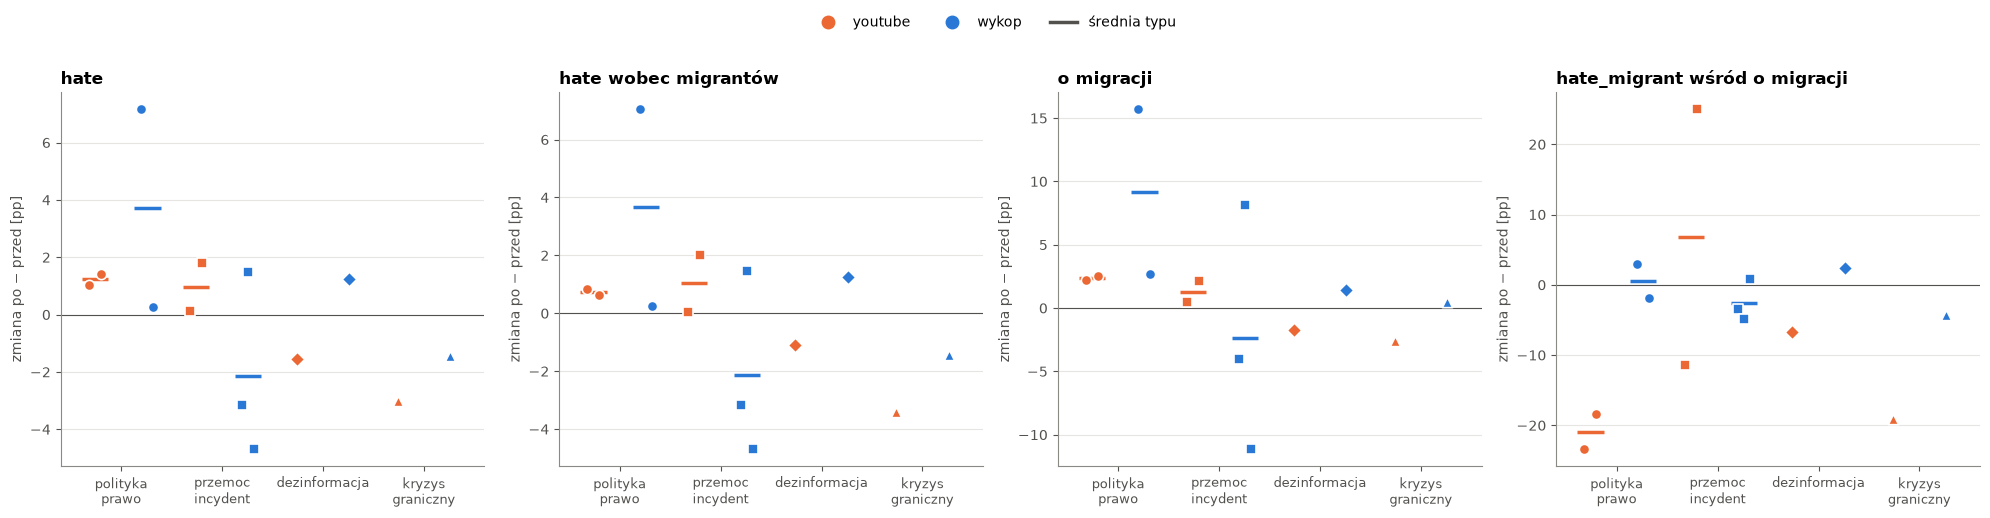

In [17]:
fig, axes = plt.subplots(1, len(LABEL_SETS), figsize=(20, 5.2))
for ax, name in zip(axes, LABEL_SETS):
    for pi, p in enumerate(PL):
        e = eff[(eff["etykieta"] == name) & (eff["platform"] == p)]
        for xi, t in enumerate(TYPE_ORDER):
            g = e[e["typ"] == t].dropna(subset=["różnica pp"])
            if g.empty:
                continue
            x0 = xi + offs[pi] * 1.3
            xs = x0 + np.linspace(-0.06, 0.06, len(g)) if len(g) > 1 else np.array([x0])
            ax.scatter(xs, g["różnica pp"], s=55, color=PLATFORM_COLORS[p], marker=TYPE_MARKERS[t],
                       edgecolor="white", linewidth=1.2, zorder=3)
            if len(g) > 1:
                ax.hlines(g["różnica pp"].mean(), x0 - 0.13, x0 + 0.13, color=PLATFORM_COLORS[p], lw=2.5)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(range(len(TYPE_ORDER)), [t.replace(" / ", "\n").replace(" ", "\n") for t in TYPE_ORDER], fontsize=9)
    ax.set_xlim(-0.6, len(TYPE_ORDER) - 0.4)
    ax.set_ylabel("zmiana po − przed [pp]")
    ax.set_title(SHORT_NAMES[name])
platform_legend(fig, extra=[(plt.Line2D([], [], color=INK2, lw=2.5), "średnia typu")])
plt.show()

## 5. Przebieg w czasie – platformy na wspólnej osi

Dla każdej platformy i wydarzenia: dzienny odsetek **minus własna średnia sprzed wydarzenia** (pp), wygładzony średnią
kroczącą `ROLL_DAYS` dni. Cienkie linie = pojedyncze wydarzenia, gruba = średnia wydarzeń na platformie.
Dzięki odjęciu poziomu bazowego platformy o bardzo różnych poziomach da się porównać na jednej osi.

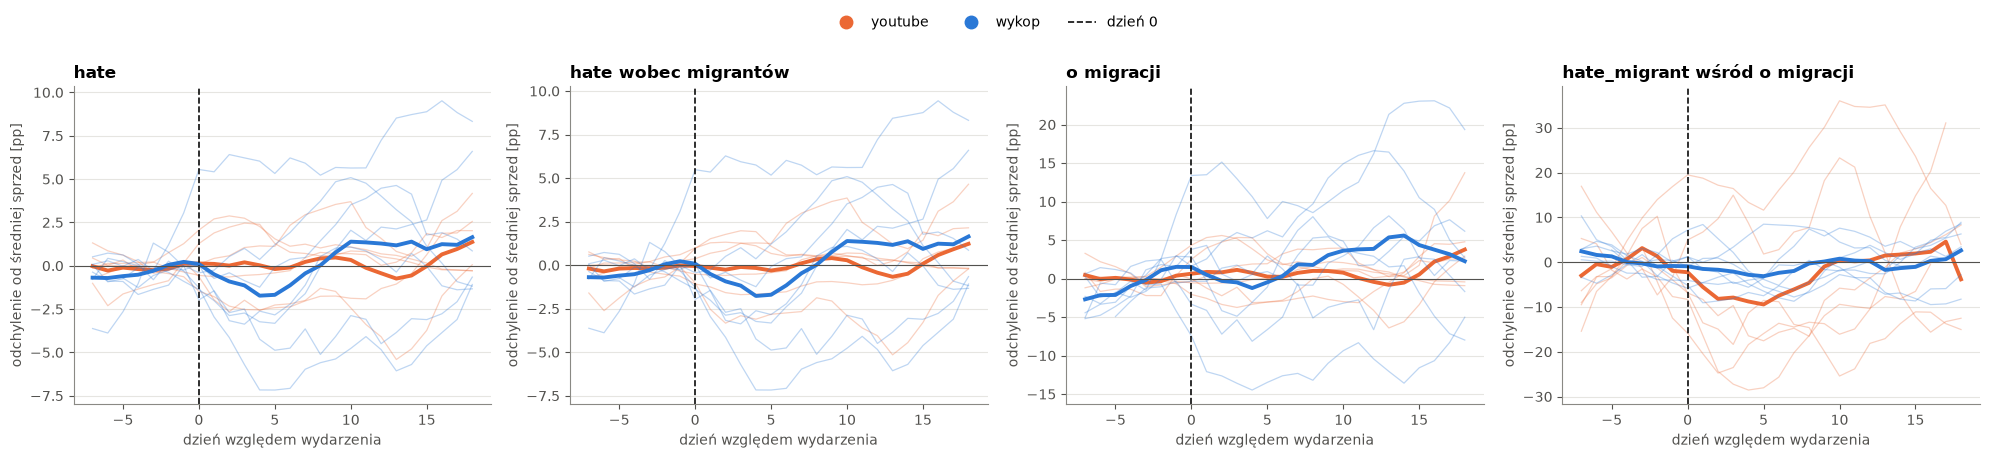

In [18]:
fig, axes = plt.subplots(1, len(LABEL_SETS), figsize=(20, 4.6))
for ax, (name, (col, cond)) in zip(axes, LABEL_SETS.items()):
    den = cond or "n"
    for p in PL:
        curves = {}
        for ev in EVENT_ORDER:
            g = daily[(daily["platform"] == p) & (daily["event"] == ev)].set_index("relative_day")
            if g.empty:
                continue
            base = g.loc[g["okres"] == "przed", col].sum() / max(g.loc[g["okres"] == "przed", den].sum(), 1)
            share = (g[col] / g[den]).where(g[den] >= MIN_DAILY_N)
            share = share.reindex(range(WINDOW.loc[ev, "od"], WINDOW.loc[ev, "do"] + 1))
            s = (100 * (share - base)).rolling(ROLL_DAYS, center=True, min_periods=2).mean()
            curves[ev] = s
            ax.plot(s.index, s.values, color=PLATFORM_COLORS[p], lw=0.9, alpha=0.3)
        if curves:
            avg = pd.DataFrame(curves).mean(axis=1)
            ax.plot(avg.index, avg.values, color=PLATFORM_COLORS[p], lw=2.8)
    ax.axvline(0, color=INK, ls="--", lw=1.2)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xlabel("dzień względem wydarzenia")
    ax.set_ylabel("odchylenie od średniej sprzed [pp]")
    ax.set_title(SHORT_NAMES[name])
platform_legend(fig, extra=[(plt.Line2D([], [], color=INK, ls="--", lw=1.2), "dzień 0")])
plt.show()

## 6. Liczba komentarzy: czy po zsumowaniu platform widać ogólny przyrost hejtu?

**6.1 Aktywność** – komentarzy/dzień i komentarzy z etykietą/dzień przed i po, krotność wzrostu.

**6.2 Wolumen (liczby bezwzględne)** – regresja Poissona na dziennych liczbach `liczba ~ po + C(platforma:wydarzenie)`
z odpornymi błędami (HC0). **IRR** = ile razy więcej komentarzy danego rodzaju pojawia się dziennie po wydarzeniu.
Jeśli IRR dla hejtu > IRR dla wszystkich komentarzy, to hejtu przybywa szybciej niż samej dyskusji
(czyli rośnie też odsetek).

**6.3 Wszystkie platformy razem** – komentarze ze wszystkich platform w jednej puli: czy łącznie widać wzrost?

⚠️ **Paradoks Simpsona.** Platformy mają bardzo różne poziomy (Wykop ~14% `hate`, YouTube ~2–3%) i różne proporcje
komentarzy przed/po. Jeśli po wydarzeniu przybywa głównie komentarzy z platformy o niskim poziomie, surowy odsetek w puli
spadnie, nawet gdy na każdej platformie z osobna rośnie. Dlatego efekt puli liczymy regresją `y ~ po + C(platform)`
(porównanie przed/po **w obrębie platformy**, wyniki zsumowane), a surową zmianę w pp pokazujemy tylko poglądowo,
obok **średniej zmian platform (po równo)**.

In [19]:
act = (daily.groupby(["platform", "event", "okres"])
       .agg(dni=("relative_day", "nunique"), n=("n", "sum"), hate=("hate", "sum"), hate_migrant=("hate_migrant", "sum"),
            migrant=("migrant", "sum")))
per_day = act[["n", "hate", "hate_migrant", "migrant"]].div(act["dni"], axis=0).unstack("okres")
act_tab = pd.DataFrame(index=per_day.index)
for c, lab in [("n", "komentarze"), ("migrant", "o migracji"), ("hate", "hate"), ("hate_migrant", "hate_migrant")]:
    act_tab[f"{lab}/dzień przed"] = per_day[(c, "przed")]
    act_tab[f"{lab}/dzień po"] = per_day[(c, "po")]
    act_tab[f"{lab} wzrost ×"] = per_day[(c, "po")] / per_day[(c, "przed")]
act_tab = act_tab.reindex(pd.MultiIndex.from_product([PL, EVENT_ORDER])).dropna(how="all")
display(act_tab.round(2))

komentarze/dzień przed  komentarze/dzień po  komentarze wzrost ×  o migracji/dzień przed  o migracji/dzień po  o migracji wzrost ×  hate/dzień przed  hate/dzień po  hate wzrost ×  hate_migrant/dzień przed  \
youtube Pakt_Azyl_PE                               5138.14              2883.42                 0.56                   37.43                84.47                 2.26             30.29          47.21           1.56                     25.71   
        Bojka_Srem                                 3994.14              4309.74                 1.08                   78.43               103.68                 1.32             66.14          76.95           1.16                     58.86   
        Strategia_Migracyjna                       3671.29              4833.68                 1.32                   79.29               226.68                 2.86             50.71         135.37           2.67                     46.71   
        Dezinformacja_Krakow                       2510.43              2135.11                 0.85                  129.29                72.84                 0.56             89.00          42.58           0.48                     64.43   
        Ceuta_Masowe_Przekroczenie                 2423.00              2639.58                 1.09                  273.00               228.00                 0.84            197.29         135.21           0.69                    183.29   
        Atak_Kamienna_Gora                         2119.00              4979.37                 2.35                   61.71               249.84                 4.05             34.57         171.42           4.96                     22.29   
wykop   Pakt_Azyl_PE                                494.00               457.42                 0.93                   76.00               142.16                 1.87             30.00          60.53           2.02                     29.71   
        Smierc_Zolnierza                            440.40               486.05                 1.10                  203.80               205.32                 1.01             86.00          79.53           0.92                     86.00   
        Bojka_Srem                                  486.86               469.37                 0.96                  129.14               162.58                 1.26             50.14          55.26           1.10                     50.14   
        Strategia_Migracyjna                        461.00               409.05                 0.89                  185.29               175.26                 0.95             72.86          65.74           0.90                     72.86   
        Dezinformacja_Krakow                        352.57               340.21                 0.96                   92.00                93.68                 1.02             37.00          39.95           1.08                     37.00   
        Ceuta_Masowe_Przekroczenie                  511.29               431.79                 0.84                  195.71               167.32                 0.85             93.14          72.47           0.78                     93.14   
        Atak_Kamienna_Gora                          417.71               399.74                 0.96                  168.29               116.47                 0.69             74.29          52.32           0.70                     74.29   

                                    hate_migrant/dzień po  hate_migrant wzrost ×  
youtube Pakt_Azyl_PE                                38.26                   1.49  
        Bojka_Srem                                  66.00                   1.12  
        Strategia_Migracyjna                        91.95                   1.97  
        Dezinformacja_Krakow                        31.37                   0.49  
        Ceuta_Masowe_Przekroczenie                 109.68                   0.60  
        Atak_Kamienna_Gora                         152.63                   6.85  
wykop   Pakt_Azyl_PE                  

In [20]:
# pełna siatka dni (dni bez komentarzy = 0), żeby Poisson widział też "puste" dni
grid = pd.concat([pd.DataFrame({"platform": p, "event": ev,
                                "relative_day": range(WINDOW.loc[ev, "od"], WINDOW.loc[ev, "do"] + 1)})
                  for p in PL for ev in EVENT_ORDER if ((daily["platform"] == p) & (daily["event"] == ev)).any()])
dgrid = (grid.merge(daily.drop(columns="okres"), on=["platform", "event", "relative_day"], how="left")
         .fillna({"n": 0, "migrant": 0, "hate": 0, "hate_migrant": 0}))
dgrid["po"] = (dgrid["relative_day"] >= POST_FROM_DAY).astype(int)
dgrid["pe"] = dgrid["platform"] + ":" + dgrid["event"]


def irr(d, col):
    m = smf.glm(f"{col} ~ po + C(pe)", data=d, family=sm.families.Poisson()).fit(cov_type="HC0")
    b, se = m.params["po"], m.bse["po"]
    return np.exp(b), np.exp(b - 1.96 * se), np.exp(b + 1.96 * se), m.pvalues["po"]


vol_rows = []
for scope in [*PL, "WSZYSTKIE platformy"]:
    d = dgrid if scope.startswith("WSZYSTKIE") else dgrid[dgrid["platform"] == scope]
    for col, lab in [("n", "wszystkie komentarze"), ("migrant", "o migracji"), ("hate", "hate"), ("hate_migrant", "hate_migrant")]:
        r, lo_, hi_, p = irr(d, col)
        vol_rows.append({"zakres": scope, "liczba dzienna": lab, "IRR (po/przed)": r, "lo": lo_, "hi": hi_, "p": p})
vol = pd.DataFrame(vol_rows)
vol["p (Holm)"] = holm(vol["p"]).values
display(fmt_p(vol.set_index(["zakres", "liczba dzienna"]), 3))

IRR (po/przed)     lo     hi       p p (Holm)
zakres              liczba dzienna                                                     
youtube             wszystkie komentarze           1.097  0.913  1.318   0.324        1
                    o migracji                     1.465  1.063  2.018  0.0195    0.234
                    hate                           1.301  0.921  1.837   0.136        1
                    hate_migrant                   1.221  0.839  1.777   0.297        1
wykop               wszystkie komentarze           0.941  0.867  1.022    0.15        1
                    o migracji                     1.012  0.900  1.138    0.84        1
                    hate                           0.962  0.847  1.092   0.547        1
                    hate_migrant                   0.960  0.846  1.090   0.532        1
WSZYSTKIE platformy wszystkie komentarze           1.076  0.916  1.264   0.372        1
                    o migracji                     1.192  1.020  1.393  0.0274    0.301
                    hate                           1.140  0.934  1.391   0.198        1
                    hate_migrant                   1.087  0.890  1.327   0.412        1

In [21]:
# 6.3 pula wszystkich platform: efekt każdego wydarzenia, przed/po porównywane w obrębie platformy
all_rows = []
for ev in EVENT_ORDER:
    d_ev = all_df[all_df["event"] == ev]
    for name, (col, cond) in LABEL_SETS.items():
        d = d_ev[d_ev[cond]] if cond else d_ev
        e = eff[(eff["etykieta"] == name) & (eff["event"] == ev)].dropna(subset=["log OR"])
        d = d[d["platform"].isin(e["platform"])]  # tylko platformy z wiarygodnym efektem
        if e.empty:
            continue
        pre, post = d.loc[d["po"] == 0, col], d.loc[d["po"] == 1, col]
        formula = "y ~ po + C(platform)" if d["platform"].nunique() > 1 else "y ~ po"
        _, m = wald(d, col, formula, lambda n: n == "po")
        b, se = (m.params["po"], m.bse["po"]) if m is not None else (np.nan, np.nan)
        all_rows.append({"etykieta": name, "event": ev, "platformy": ", ".join(e["platform"]),
                         "zmiana pp (surowa pula)": 100 * (post.mean() - pre.mean()),
                         "zmiana pp (platformy po równo)": e["różnica pp"].mean(),
                         "log OR": b, "se": se, "OR (w obrębie platform)": np.exp(b),
                         "OR lo": np.exp(b - 1.96 * se), "OR hi": np.exp(b + 1.96 * se),
                         "p": m.pvalues["po"] if m is not None else np.nan})
eff_all = pd.DataFrame(all_rows)
eff_all["p (Holm)"] = eff_all.groupby("etykieta")["p"].transform(holm)
eff_all["istotne"] = eff_all["p (Holm)"] < ALPHA

pooled_rows = []
for name, (col, cond) in LABEL_SETS.items():
    e = eff_all[eff_all["etykieta"] == name]
    m = meta_random(e["log OR"], e["se"])
    d = all_df[all_df[cond]] if cond else all_df
    _, fe = wald(d, col, "y ~ po + C(pe)", lambda n: n == "po")
    up = e["OR (w obrębie platform)"] > 1
    pooled_rows.append({"etykieta": name, "wzrost w": f"{int(up.sum())}/{len(e)}",
                        "istotny wzrost w": f"{int((e['istotne'] & up).sum())}/{len(e)}",
                        "średnia zmiana pp (surowa pula)": e["zmiana pp (surowa pula)"].mean(),
                        "średnia zmiana pp (platformy po równo)": e["zmiana pp (platformy po równo)"].mean(),
                        "OR łączny (meta)": np.exp(m["mu"]), "OR lo": np.exp(m["lo"]), "OR hi": np.exp(m["hi"]),
                        "p meta": m["p"], "I²": m["I2"],
                        "OR model wspólny": np.exp(fe.params["po"]) if fe is not None else np.nan,
                        "p model wspólny": fe.pvalues["po"] if fe is not None else np.nan})
pooled_all = pd.DataFrame(pooled_rows).set_index("etykieta")
pooled_all["p meta (Holm)"] = holm(pooled_all["p meta"]).values
print("Wszystkie platformy razem – efekt każdego wydarzenia (OR: przed/po w obrębie platformy):")
display(fmt_p(eff_all.drop(columns=["log OR", "se"]).set_index(["etykieta", "event"]), 3))
print("Wszystkie platformy i wydarzenia razem:")
display(fmt_p(pooled_all, 3))

Wszystkie platformy razem – efekt każdego wydarzenia (OR: przed/po w obrębie platformy):


,,platformy,zmiana pp (surowa pula),zmiana pp (platformy po równo),OR (w obrębie platform),OR lo,OR hi,p,p (Holm),istotne
etykieta,event,,,,,,,,,
hate,Pakt_Azyl_PE,"youtube, wykop",2.154,4.104,2.583,1.801,3.704,2.51e-07,1.76e-06,True
hate_migrant,Pakt_Azyl_PE,"youtube, wykop",1.949,3.935,2.498,1.787,3.491,8.36e-08,5.85e-07,True
migrant,Pakt_Azyl_PE,"youtube, wykop",4.770,8.947,3.062,1.942,4.827,1.45e-06,1.02e-05,True
hate_migrant | migrant,Pakt_Azyl_PE,"youtube, wykop",-5.625,-10.241,0.786,0.574,1.078,0.136,0.407,False
hate,Smierc_Zolnierza,wykop,-3.166,-3.166,0.806,0.599,1.085,0.156,0.778,False
hate_migrant,Smierc_Zolnierza,wykop,-3.166,-3.166,0.806,0.599,1.085,0.156,0.783,False
migrant,Smierc_Zolnierza,wykop,-4.035,-4.035,0.849,0.615,1.172,0.32,1,False
hate_migrant | migrant,Smierc_Zolnierza,wykop,-3.465,-3.465,0.866,0.660,1.136,0.299,0.598,False
hate,Bojka_Srem,"youtube, wykop",0.171,0.802,1.113,0.765,1.619,0.577,0.882,False


Wszystkie platformy i wydarzenia razem:


,wzrost w,istotny wzrost w,średnia zmiana pp (surowa pula),średnia zmiana pp (platformy po równo),OR łączny (meta),OR lo,OR hi,p meta,I²,OR model wspólny,p model wspólny,p meta (Holm)
etykieta,,,,,,,,,,,,
hate,4/7,1/7,-0.618,-0.177,1.138,0.726,1.783,0.508,0.815,1.060,0.63,1
hate_migrant,4/7,1/7,-0.735,-0.244,1.104,0.714,1.709,0.598,0.822,1.015,0.903,1
migrant,4/7,1/7,-0.489,0.862,1.226,0.789,1.907,0.301,0.778,1.182,0.131,0.904
hate_migrant | migrant,1/7,0/7,-3.427,-4.696,0.835,0.650,1.072,0.128,0.621,0.795,0.0075,0.513


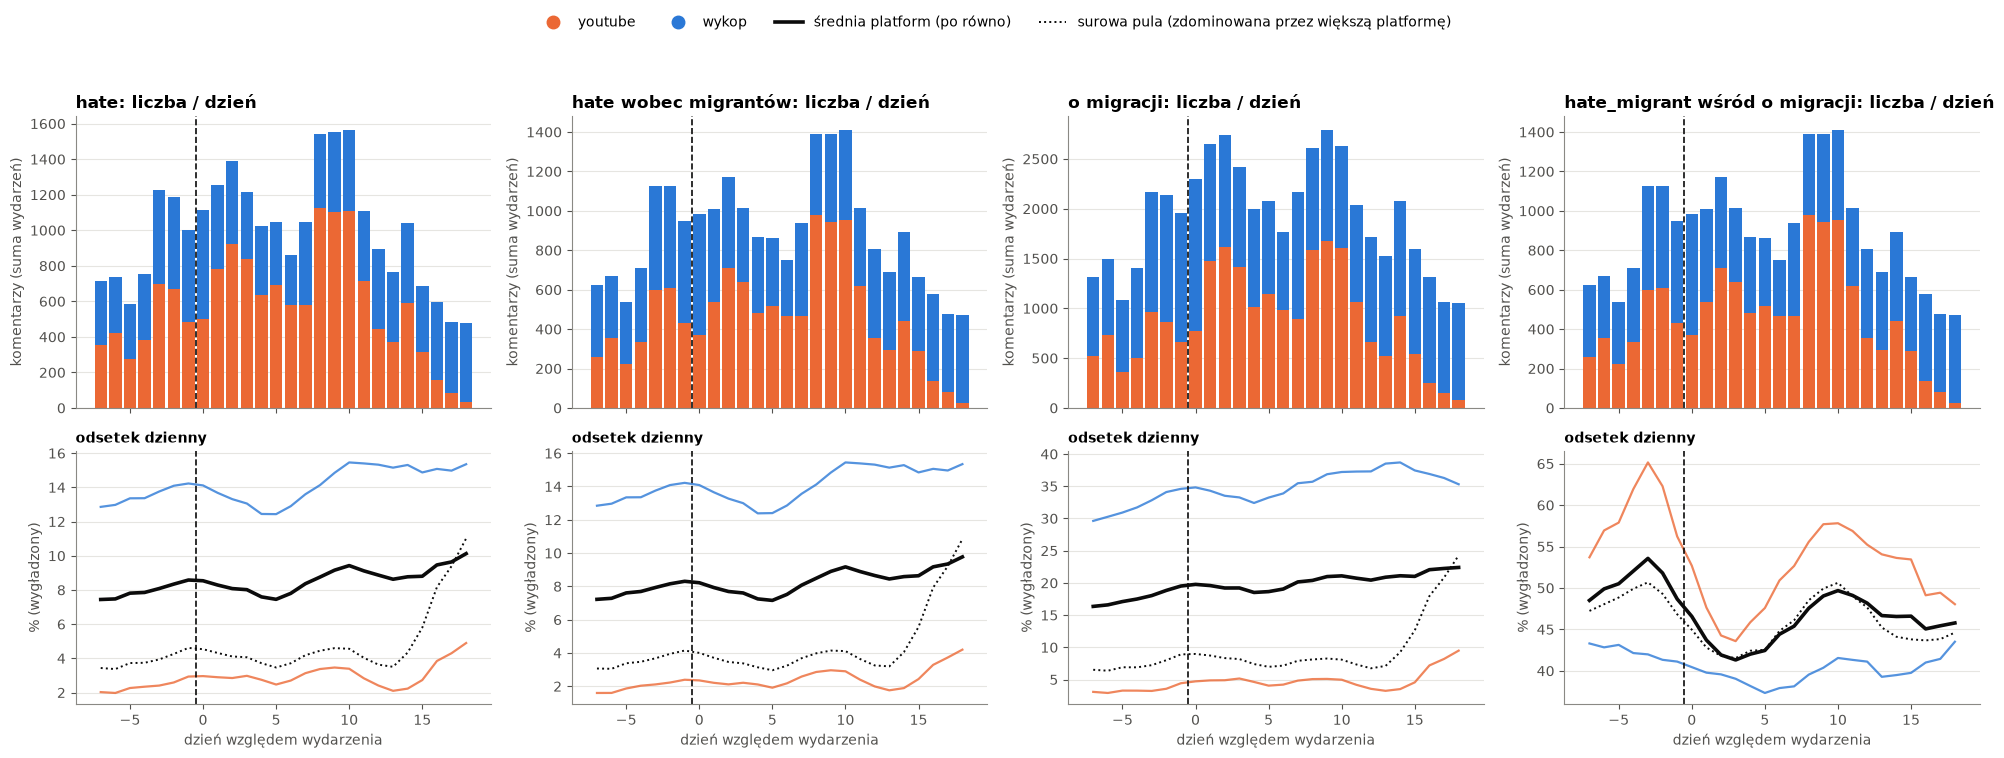

In [22]:
fig, axes = plt.subplots(2, len(LABEL_SETS), figsize=(20, 7.6), sharex=True, gridspec_kw={"height_ratios": [1.15, 1]})
days = range(int(WINDOW["od"].min()), int(WINDOW["do"].max()) + 1)
tot = dgrid.groupby(["relative_day", "platform"])[["n", "migrant", "hate", "hate_migrant"]].sum()
for j, (name, (col, cond)) in enumerate(LABEL_SETS.items()):
    den = cond or "n"
    ax = axes[0, j]
    bottom = np.zeros(len(days))
    for p in PL:
        v = tot[col].xs(p, level="platform").reindex(days, fill_value=0).values
        ax.bar(list(days), v, bottom=bottom, width=0.85, color=PLATFORM_COLORS[p])
        bottom += v
    ax.axvline(-0.5, color=INK, ls="--", lw=1.2)
    ax.set_title(f"{SHORT_NAMES[name]}: liczba / dzień")
    ax.set_ylabel("komentarzy (suma wydarzeń)")
    ax = axes[1, j]
    raw = tot.groupby("relative_day")[[col, den]].sum()
    raw = (100 * raw[col] / raw[den]).reindex(days)
    shares = {}
    for p in PL:
        s = tot.xs(p, level="platform").reindex(days)
        shares[p] = (100 * s[col] / s[den]).where(s[den] >= MIN_DAILY_N)
        ax.plot(list(days), shares[p].rolling(ROLL_DAYS, center=True, min_periods=2).mean(),
                color=PLATFORM_COLORS[p], lw=1.6, alpha=0.8)
    ax.plot(list(days), pd.DataFrame(shares).mean(axis=1).rolling(ROLL_DAYS, center=True, min_periods=2).mean(),
            color=INK, lw=2.6)
    ax.plot(list(days), raw.rolling(ROLL_DAYS, center=True, min_periods=2).mean(), color=INK, lw=1.4, ls=":")
    ax.axvline(-0.5, color=INK, ls="--", lw=1.2)
    ax.set_ylabel("% (wygładzony)")
    ax.set_xlabel("dzień względem wydarzenia")
    ax.set_title("odsetek dzienny", fontsize=10)
platform_legend(fig, extra=[(plt.Line2D([], [], color=INK, lw=2.6), "średnia platform (po równo)"),
                            (plt.Line2D([], [], color=INK, lw=1.4, ls=":"), "surowa pula (zdominowana przez większą platformę)")])
plt.show()

In [23]:
# czy wydarzenia, które bardziej rozkręciły dyskusję, mają większy wzrost hejtu? (wszystkie pary platforma–wydarzenie)
sp_rows = []
for name in ["hate", "hate_migrant", "migrant", "hate_migrant | migrant"]:
    e = eff[eff["etykieta"] == name].set_index(["platform", "event"])["różnica pp"]
    x = pd.concat([act_tab["komentarze wzrost ×"], e], axis=1, join="inner").dropna()
    rho, p = stats.spearmanr(x.iloc[:, 0], x.iloc[:, 1])
    sp_rows.append({"etykieta": name, "n (platforma×wydarzenie)": len(x), "Spearman rho": rho, "p": p,
                    **{f"rho {pl}": stats.spearmanr(x.loc[pl].iloc[:, 0], x.loc[pl].iloc[:, 1])[0]
                       for pl in PL if pl in x.index.get_level_values(0) and len(x.loc[pl]) > 2}})
print("Wzrost aktywności (komentarze/dzień po ÷ przed) vs zmiana odsetka etykiety:")
display(fmt_p(pd.DataFrame(sp_rows).set_index("etykieta"), 3))

Wzrost aktywności (komentarze/dzień po ÷ przed) vs zmiana odsetka etykiety:


,n (platforma×wydarzenie),Spearman rho,p,rho youtube,rho wykop
etykieta,,,,,
hate,13,0.126,0.681,0.486,-0.071
hate_migrant,13,0.055,0.859,0.257,-0.071
migrant,13,-0.154,0.616,0.143,-0.214
hate_migrant | migrant,13,0.154,0.616,0.486,0.036


## 7. Słownictwo hejtu – porównanie platform

Tokenizacja jak w notebookach pojedynczych wydarzeń (małe litery, bez linków, ≥ 3 litery, bez stop-słów, bez lematyzacji).

- **7.1** najczęstsze słowa w `hate_migrant` na każdej platformie,
- **7.2** słowa **charakterystyczne dla platformy** – częstsze w hejcie tej platformy niż na pozostałych
  (ważony log-odds ratio z priorem Dirichleta, Monroe i in. 2008; `z` > 2 ≈ wyraźnie częstsze),
- **7.3** podobieństwo słownictwa (Jaccard top-100 słów) między platformami – ogółem i w każdym wydarzeniu,
- **7.4** słowa, które **rosną po wydarzeniu** na każdej platformie,
- **7.5** kogo obrażano – grupy wymieniane w hejcie na każdej platformie.

In [24]:
STOPWORDS_PL = set('''
a aby ach acz aczkolwiek aj albo ale ależ ani aż bardziej bardzo bez bo bowiem by byli bym bynajmniej być był była było były będzie będą
cali cała cały chce chcą ci cię ciebie co cokolwiek coraz coś czasami czasem czemu czy czyli często daleko dla dlaczego dlatego do dobrze
dokąd dość dużo dwa dwaj dwie dwoje dziś dzisiaj gdy gdyby gdyż gdzie gdziekolwiek gdzieś go i ich ile im inna inne inny innych iż ja ją
jak jakaś jakby jaki jakichś jakie jakiś jakiż jakkolwiek jako jakoś je jeden jedna jedno jednak jednakże jego jej jemu jest jestem jeszcze
jeśli jeżeli już ją każdy kiedy kilka kimś kto ktokolwiek ktoś która które którego której który których którym którzy ku lat lecz lub
ma mają mam mamy mało mi mimo między mną mnie mogą moi moim moja moje może możliwe można mój mu musi my na nad nam nami nas nasi nasz nasza
nasze naszego naszych natomiast natychmiast nawet nic nich nie niech niego niej niemu nigdy nim nimi niż no o obok od około on ona one oni
ono oraz oto owszem pan pana pani po pod podczas pomimo ponad ponieważ powinien powinna powinni powinno poza prawie przecież przed przede
przedtem przez przy roku również sam sama są się skąd sobie sobą sposób swoje ta tak taka taki takie także tam te tego tej temu ten teraz
też to tobą tobie toteż trzeba tu tutaj twoi twoim twoja twoje twym twój ty tych tylko tym u w wam wami was wasz wasza wasze we według
wiele wielu więc więcej wszyscy wszystkich wszystkie wszystkim wszystko wtedy wy właśnie z za zapewne zawsze ze zł znowu znów został żaden
żadna żadne żadnych że żeby tez juz sie jak ktory ktora ktore bylo byl beda bedzie moze takze zeby ze tylko wiec niz przez tego tym jeszcze
tych tej mnie mieć mają ma mial miał było będą bylo były jakis jakies cos nikt nikogo niczego wszystkiego swój swoją swojej swoich swoim
naszym tymi takich takiej takim tamtych coś ktoś kogoś czegoś bym byś byście byśmy będę będziesz będziemy jestes jesteś jesteśmy
http https www com html pdf amp quot xd xdd xddd lenny bo tam tu oni ich sa sā też dla gdzie potem teraz chyba raczej
'''.split())

URL_RE = re.compile(r"https?://\S+|www\.\S+|@\w+")
TOKEN_RE = re.compile(r"[a-ząćęłńóśźż]{3,}")


def tokenize(text):
    return [t for t in TOKEN_RE.findall(URL_RE.sub(" ", text.lower())) if t not in STOPWORDS_PL]


def count_words(texts):
    return Counter(t for txt in texts for t in tokenize(txt))


def log_odds(c1, c2, prior, min_count=5):
    """Ważony log-odds ratio z informatywnym priorem Dirichleta (Monroe i in. 2008); z > 0 = częstsze w c1."""
    n1, n2, a0 = sum(c1.values()), sum(c2.values()), sum(prior.values())
    rows = []
    for w, y1 in c1.items():
        if y1 < min_count:
            continue
        a, y2 = prior[w], c2.get(w, 0)
        delta = np.log((y1 + a) / (n1 + a0 - y1 - a)) - np.log((y2 + a) / (n2 + a0 - y2 - a))
        rows.append((w, y1, y2, delta / np.sqrt(1 / (y1 + a) + 1 / (y2 + a))))
    return pd.DataFrame(rows, columns=["słowo", "n", "n porównanie", "z"]).sort_values("z", ascending=False)


hm = all_df[all_df["hate_migrant"]]
counts = {p: count_words(hm.loc[hm["platform"] == p, "text"]) for p in PL}
counts_ev = {(p, ev): count_words(g["text"]) for (p, ev), g in hm.groupby(["platform", "event"])}
total = sum(counts.values(), Counter())

print("7.1 Najczęstsze słowa w hate_migrant na każdej platformie:")
display(pd.DataFrame({f"{p} ({(hm['platform'] == p).sum():,} kom.)": [f"{w} ({n})" for w, n in counts[p].most_common(TOP_N_WORDS)]
                      for p in PL}, index=range(1, TOP_N_WORDS + 1)))

7.1 Najczęstsze słowa w hate_migrant na każdej platformie:


,"youtube (12,117 kom.)","wykop (11,004 kom.)"
1,polski (1675),ukraińców (495)
2,polaków (1415),polsce (494)
3,polsce (1394),polski (494)
4,ukraińców (1033),ukraińcy (459)
5,polacy (972),ludzi (431)
6,polska (779),kraju (431)
7,ukraińcy (747),polaków (408)
8,kraju (719),ludzie (403)
9,ludzie (675),polacy (356)
10,ludzi (659),ukry (308)


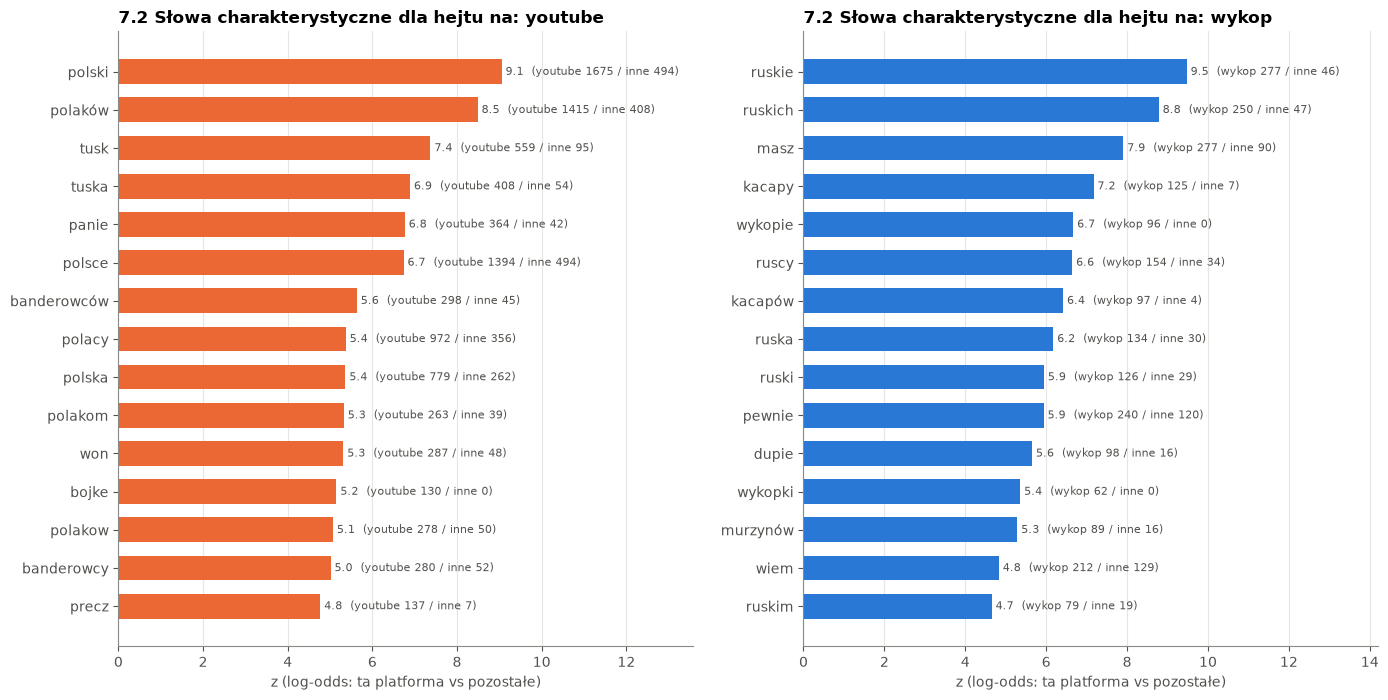

In [25]:
if len(PL) >= 2:
    fig, axes = plt.subplots(1, len(PL), figsize=(7 * len(PL), 0.38 * TOP_N_WORDS + 1.4))
    for ax, p in zip(np.atleast_1d(axes), PL):
        t = log_odds(counts[p], total - counts[p], total, min_count=10).head(TOP_N_WORDS)
        ax.barh(t["słowo"][::-1], t["z"][::-1], color=PLATFORM_COLORS[p], height=0.65)
        for yi, (z, n1, n0) in enumerate(zip(t["z"][::-1], t["n"][::-1], t["n porównanie"][::-1])):
            ax.text(z, yi, f" {z:.1f}  ({p} {n1} / inne {n0})", va="center", color=INK2, fontsize=8)
        ax.margins(x=0.5)
        ax.grid(axis="y", visible=False)
        ax.grid(axis="x", visible=True)
        ax.set_xlabel("z (log-odds: ta platforma vs pozostałe)")
        ax.set_title(f"7.2 Słowa charakterystyczne dla hejtu na: {p}")
    plt.tight_layout()
    plt.show()

In [26]:
def top_set(c, k=100):
    return {w for w, _ in c.most_common(k)}


if len(PL) >= 2:
    jac = {}
    for a, b in pairs:
        col = f"{a} vs {b}"
        jac[col] = {"WSZYSTKIE": len(top_set(counts[a]) & top_set(counts[b])) / len(top_set(counts[a]) | top_set(counts[b]))}
        for ev in EVENT_ORDER:
            if (a, ev) in counts_ev and (b, ev) in counts_ev:
                sa, sb = top_set(counts_ev[(a, ev)]), top_set(counts_ev[(b, ev)])
                jac[col][ev] = len(sa & sb) / len(sa | sb)
    print("7.3 Podobieństwo słownictwa hejtu (Jaccard top-100 słów; 1 = identyczne, 0 = brak wspólnych):")
    display(pd.DataFrame(jac).round(2))

    # słowa wspólne vs specyficzne dla wydarzenia – przykłady
    print("Wspólne słowa w top-100 hejtu (wszystkie wydarzenia):")
    common = set.intersection(*[top_set(counts[p]) for p in PL])
    print(", ".join(w for w, _ in total.most_common() if w in common)[:1500])

7.3 Podobieństwo słownictwa hejtu (Jaccard top-100 słów; 1 = identyczne, 0 = brak wspólnych):


,youtube vs wykop
WSZYSTKIE,0.49
Pakt_Azyl_PE,0.30
Bojka_Srem,0.34
Strategia_Migracyjna,0.32
Dezinformacja_Krakow,0.25
Ceuta_Masowe_Przekroczenie,0.35
Atak_Kamienna_Gora,0.32


Wspólne słowa w top-100 hejtu (wszystkie wydarzenia):
polski, polsce, polaków, ukraińców, polacy, ukraińcy, kraju, ludzi, ludzie, polska, ukrainy, dzieci, ukry, siebie, pis, kraj, ukrainiec, ukrainie, niemcy, ukraina, samo, imigrantów, sami, dalej, wojny, tyle, granicy, polskie, rząd, europy, pracy, polak, lepiej, polskich, problem, robią, ukraincy, wojna, ukrainę, czas, mówi, robi, afryki, skoro, rosji, domu, prawo, niemiec, państwo, czego, prawa, mieli, ukrów, zamiast, chodzi, rosja, kobiety, imigranci, granicę, widać, prawda, czym, maja, usa, niestety, strony


In [27]:
grow_tabs, fall_tabs = {}, {}
for p in PL:
    g = hm[hm["platform"] == p]
    c_pre, c_post = count_words(g.loc[g["okres"] == "przed", "text"]), count_words(g.loc[g["okres"] == "po", "text"])
    lo_ = log_odds(c_post, c_pre, c_pre + c_post, min_count=10)
    grow_tabs[p] = [f"{w} (z={z:.1f})" for w, z in zip(lo_["słowo"].head(TOP_N_WORDS), lo_["z"].head(TOP_N_WORDS))]
    lo_ = lo_.sort_values("z").head(TOP_N_WORDS)
    fall_tabs[p] = [f"{w} (z={z:.1f})" for w, z in zip(lo_["słowo"], lo_["z"])]
pad = lambda v: v + [""] * (TOP_N_WORDS - len(v))
print("7.4 Słowa w hate_migrant, które najbardziej ROSNĄ po wydarzeniu (wszystkie wydarzenia razem):")
display(pd.DataFrame({p: pad(v) for p, v in grow_tabs.items()}, index=range(1, TOP_N_WORDS + 1)))
print("... i które najbardziej MALEJĄ:")
display(pd.DataFrame({p: pad(v) for p, v in fall_tabs.items()}, index=range(1, TOP_N_WORDS + 1)))

7.4 Słowa w hate_migrant, które najbardziej ROSNĄ po wydarzeniu (wszystkie wydarzenia razem):


,youtube,wykop
1,panie (z=2.5),inżynierów (z=1.9)
2,tusk (z=2.5),referendum (z=1.8)
3,europy (z=2.3),migrantów (z=1.6)
4,imigranci (z=2.2),imigracji (z=1.5)
5,hiszpanii (z=2.1),ubogacenie (z=1.4)
6,powodzian (z=2.1),usa (z=1.4)
7,dyj (z=2.0),musiał (z=1.4)
8,hiszpanie (z=1.9),szwecji (z=1.3)
9,afryki (z=1.8),matki (z=1.3)
10,płacz (z=1.8),powoli (z=1.3)


... i które najbardziej MALEJĄ:


,youtube,wykop
1,bojke (z=-6.0),zbrodnie (z=-1.9)
2,ukrainiec (z=-4.7),polaków (z=-1.7)
3,izrael (z=-4.4),ruscy (z=-1.7)
4,arleta (z=-4.0),ukraińcem (z=-1.6)
5,materiał (z=-3.9),żebyś (z=-1.5)
6,izraela (z=-3.7),dupę (z=-1.5)
7,zaatakował (z=-3.5),wojnie (z=-1.5)
8,autobusie (z=-3.3),ataki (z=-1.5)
9,kanał (z=-3.2),front (z=-1.5)
10,letni (z=-3.0),armii (z=-1.4)


### 7.5 Kogo obrażano? Grupy w hejcie wobec migrantów

Odsetek komentarzy `hate_migrant` wymieniających daną grupę (słowa kluczowe jak w notebookach pojedynczych wydarzeń;
komentarz może trafić do kilku grup). Lewy panel – platformy ogółem (przed / po), pozostałe – okres **po** w każdym wydarzeniu.

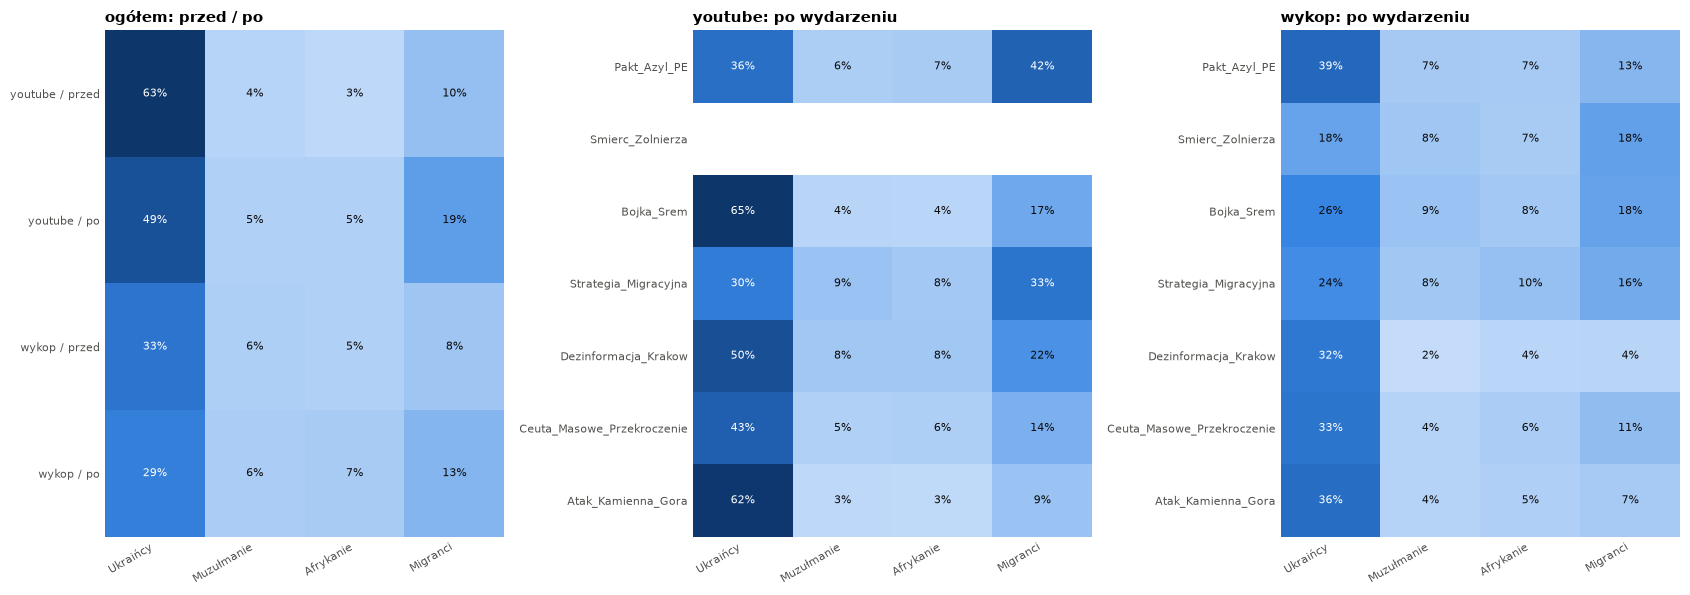

Zmiana po − przed [pp], platformy ogółem:


,Ukraińcy,Muzułmanie / Arabowie / Bliski Wschód,Afrykanie / czarnoskórzy,Migranci / uchodźcy (ogólnie)
youtube,-14.0,1.2,2.1,9.2
wykop,-4.4,0.8,1.6,4.7


In [28]:
TARGET_GROUPS = {
    "Ukraińcy": r"ukrai|ukraiń|\bukr|ukrop|bander|\bupa\b|upain|upowc|slava|sława|chachoł|chochoł",
    "Muzułmanie / Arabowie / Bliski Wschód": r"muzu?ł?m|muslim|islam|arab|allah|ciap|kozoj|talib|afga|syryj|syri|irak|turk|turc|pakist|czeczen|kebab|szariat|meczet",
    "Afrykanie / czarnoskórzy": r"murzyn|afryk|czarn|bambus|asfalt|nigeri|somal|erytre|małp|malp",
    "Migranci / uchodźcy (ogólnie)": r"migran|imigran|uchodź|uchodz|nachodź|nachodz|najeźdź|najezdz|relokac|azyl|ubogac|nielegal|przybysz|inwazj",
}
low = hm["text"].str.lower()
grp = pd.DataFrame({g: low.str.contains(rx, regex=True) for g, rx in TARGET_GROUPS.items()})
grp[["platform", "event", "okres"]] = hm[["platform", "event", "okres"]]

overall = 100 * grp.groupby(["platform", "okres"])[list(TARGET_GROUPS)].mean()
overall = overall.reindex(pd.MultiIndex.from_product([PL, ["przed", "po"]]))
by_ev = {p: 100 * grp[(grp["platform"] == p) & (grp["okres"] == "po")].groupby("event")[list(TARGET_GROUPS)].mean().reindex(EVENT_ORDER)
         for p in PL}

fig, axes = plt.subplots(1, 1 + len(PL), figsize=(6 + 5.5 * len(PL), 0.55 * len(EVENT_ORDER) + 2.2),
                         gridspec_kw={"width_ratios": [1] + [1] * len(PL)})
vmax = np.nanmax([overall.values.max(), *[t.values.max() for t in by_ev.values()]])
for ax, (title, tab) in zip(axes, [("ogółem: przed / po", overall), *[(f"{p}: po wydarzeniu", by_ev[p]) for p in PL]]):
    ax.imshow(tab.values, cmap=BLUES, aspect="auto", vmin=0, vmax=vmax)
    for (i, j), v in np.ndenumerate(tab.values):
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="white" if v > 0.45 * vmax else INK)
    ax.set_xticks(range(tab.shape[1]), [c.split(" / ")[0].split(" (")[0] for c in tab.columns], rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(len(tab)), [" / ".join(i) if isinstance(i, tuple) else i for i in tab.index], fontsize=8)
    ax.grid(False)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(title, fontsize=11)
plt.tight_layout()
plt.show()

print("Zmiana po − przed [pp], platformy ogółem:")
display((overall.xs("po", level=1) - overall.xs("przed", level=1)).round(1))

## 8. Podsumowanie H4 (generowane automatycznie)

In [29]:
for name in LABEL_SETS:
    print(f"{LABEL_NAMES[name]}:")
    for p in PL:
        r = plat[(plat["etykieta"] == name) & (plat["platform"] == p)].iloc[0]
        print(f"  {p:8s} wzrost w {r['wzrost w']} wydarzeń (istotny w {r['istotny wzrost w']}), średnio {r['średnia zmiana pp']:+.2f} pp, "
              f"OR łączny = {r['OR łączny']:.2f} [{r['OR lo']:.2f}; {r['OR hi']:.2f}], I² = {r['I²']:.0%}")
    for _, r in paired[paired["etykieta"] == name].iterrows():
        verdict = "RÓŻNICA ISTOTNA" if r["p meta (Holm)"] < ALPHA else "brak istotnej różnicy"
        print(f"  {r['para (A vs B)']}: ROR = {r['ROR łączny (A/B)']:.2f} [{r['ROR lo']:.2f}; {r['ROR hi']:.2f}], "
              f"p (Holm) = {r['p meta (Holm)']:.3g} -> {verdict}; silniej na A w {r['silniej na A w']} wydarzeń, "
              f"Wilcoxon p = {r['p Wilcoxon (pp)']:.3g}")
    if len(PL) >= 2:
        print(f"  model po × platforma: p = {model_h4.loc[name, 'p (po × platforma)']:.3g}")
    c = cmp_ev[(cmp_ev["etykieta"] == name)]
    if "platformy różne" in c:
        diff = c.loc[c["platformy różne"] == True, "event"].tolist()
        print(f"  wydarzenia z istotnie różną reakcją platform: {', '.join(diff) if diff else 'brak'}")
    r = pooled_all.loc[name]
    print(f"  wszystkie platformy razem: wzrost w {r['wzrost w']}, OR = {r['OR łączny (meta)']:.2f} "
          f"[{r['OR lo']:.2f}; {r['OR hi']:.2f}], p = {r['p meta']:.3g}\n")
if skipped:
    print("Pominięte (brak danych):", ", ".join(f"{p}/{e}" for p, e in skipped))

hate (w dyskusji o migracji):
  youtube  wzrost w 4/6 wydarzeń (istotny w 1/6), średnio -0.03 pp, OR łączny = 1.32 [0.65; 2.71], I² = 70%
  wykop    wzrost w 4/7 wydarzeń (istotny w 1/7), średnio +0.12 pp, OR łączny = 1.06 [0.74; 1.51], I² = 84%
  youtube vs wykop: ROR = 1.16 [0.57; 2.33], p (Holm) = 1 -> brak istotnej różnicy; silniej na A w 3/6 wydarzeń, Wilcoxon p = 0.562
  model po × platforma: p = 0.805
  wydarzenia z istotnie różną reakcją platform: Atak_Kamienna_Gora
  wszystkie platformy razem: wzrost w 4/7, OR = 1.14 [0.73; 1.78], p = 0.508

hate wobec migrantów:
  youtube  wzrost w 4/6 wydarzeń (istotny w 2/6), średnio -0.16 pp, OR łączny = 1.26 [0.58; 2.74], I² = 76%
  wykop    wzrost w 4/7 wydarzeń (istotny w 1/7), średnio +0.10 pp, OR łączny = 1.06 [0.74; 1.50], I² = 84%
  youtube vs wykop: ROR = 1.11 [0.50; 2.47], p (Holm) = 1 -> brak istotnej różnicy; silniej na A w 3/6 wydarzeń, Wilcoxon p = 0.562
  model po × platforma: p = 0.926
  wydarzenia z istotnie różną reakcją p

## 9. Wnioski (stan danych: YouTube + Wykop, 7 wydarzeń; Bluesky czeka na `labeled`)

Okno wspólne −7..18 dni (−5..18 dla Śmierci żołnierza). YouTube / Śmierć żołnierza jest wykluczone, bo komentarze „przed” pochodzą z **jednego filmu**.
Liczby poniżej pochodzą z bieżącego uruchomienia. Po dodaniu Bluesky lub zmianie danych trzeba je przeczytać od nowa.

1. **Poziomy różnią się bardzo, ale głównie z powodu składu treści.** Na Wykopie ~35% komentarzy dotyczy migracji, a ~14% to hejt wobec migrantów.
   Na YouTube jest to ~3–5% i ~2%, bo większość komentarzy pod filmami newsowymi dotyczy innych tematów. Natomiast **wśród komentarzy o migracji
   YouTube jest bardziej wrogi**: mediana dzienna `hate_migrant | migrant` wynosi 54–62% na YT wobec ~42% na Wykopie (Kruskal–Wallis p < 1e-7).
2. **H4 dla średniego efektu wydarzeń: brak dowodu na różnicę między platformami.** Żadna platforma nie ma istotnego wspólnego wzrostu
   (`hate` OR: YT 1.32 [0.65; 2.71], Wykop 1.06 [0.74; 1.51]). Porównanie sparowane po wydarzeniu daje ROR YT/Wykop = 1.16 [0.57; 2.33].
   Model `po × platforma` daje p = 0.81. Wynik jest taki sam dla `hate_migrant` i `migrant` oraz w oknach bez nakładania (±7 dni).
   Wyjątek, na granicy istotności: **odsetek hejtu wśród komentarzy o migracji** spada po wydarzeniach na YT (w 5 z 6 wydarzeń, OR 0.68), a na Wykopie
   jest stabilny (OR 0.95, I² = 18%). Model daje p = 0.043, ale po korekcie Holma p = 0.17.
3. **H4 na poziomie pojedynczych wydarzeń: platformy reagują różnie.** Korelacja efektów wydarzeń między platformami jest bliska 0
   (Spearman ρ od −0.2 do 0.4), więc to samo wydarzenie nie porusza obu platform tak samo:
   - **Pakt o azylu** to jedyne wydarzenie, które wyraźnie podbiło hejt na **obu** platformach (`hate_migrant` OR: YT 2.7, Wykop 2.3).
   - **Atak w Kamiennej Górze** działa przeciwnie: na YT hejt wobec migrantów rośnie (OR 2.98), na Wykopie spada (OR 0.70).
     Różnica jest istotna po korekcie (p Holm = 0.002). Na Wykopie punkt odniesienia był już podbity przez Ceutę (nakładające się okna).
   - **Ceuta** i **Dezinformacja (Kraków)**: na YT spadek (nieistotny), na Wykopie bez zmian. **Strategia migracyjna**: większy wzrost na YT, ale nieistotny.
4. **Typ wydarzenia różnicuje efekt i robi to różnie na każdej platformie.** Test `po:typ` wychodzi istotnie w obrębie każdej platformy
   (`hate`: YT p = 0.008, Wykop p = 0.001). Potrójna interakcja typ × platforma też jest istotna (`hate` p = 0.03, `hate_migrant` p = 0.02).
   **Polityka / prawo** podnosi hejt na obu platformach (OR 2.5 na YT i 1.5 na Wykopie; na Wykopie głównie przez Pakt).
   **Przemoc / incydent**: na YT wzrost, na Wykopie spadek. **Kryzys graniczny** i **dezinformacja** nie dają wzrostu nigdzie.
   ⚠️ W typie jest 1–3 wydarzeń, więc to w praktyce różnice między konkretnymi wydarzeniami.
5. **Po zsumowaniu komentarzy z platform nie widać ogólnego przyrostu hejtu.** Dzienna liczba komentarzy o migracji rośnie po wydarzeniach
   (IRR 1.19 [1.02; 1.39], p = 0.03, po korekcie Holma nieistotne). Liczba hejtu nie rośnie istotnie (IRR `hate` 1.14 [0.93; 1.39]).
   Wzrost bierze się z YouTube (więcej filmów o migracji po wydarzeniu). Wykop ma stały wolumen. Łączny efekt
   (przed/po w obrębie platformy) wynosi OR 1.14 [0.73; 1.78] dla `hate`, a wzrost jest w 4 z 7 wydarzeń. Surowy odsetek w puli jest mylący (paradoks Simpsona).
   To, że wydarzenie bardziej rozkręciło dyskusję, nie wiąże się z większym wzrostem hejtu (ρ = 0.13).
6. **Słownictwo ma wspólny rdzeń, a różnice dotyczą tematu wydarzenia.** Podobieństwo top-100 słów hejtu wynosi 0.47 ogółem, ale tylko 0.25–0.35
   w pojedynczych wydarzeniach. Wspólne są słowa o „Polakach / Ukraińcach / kraju”. Hejt na YouTube jest bardziej narodowo-polityczny: „polski / Polaków”, „tusk”, „banderowców”, „won”, „precz”.
   Na Wykopie hejt częściej dotyczy Rosjan („ruskie”, „kacapy”), ma więcej slangu serwisu („wykopie”, „wykopki”) i rasistowskich obelg („murzynów”). Po wydarzeniach na obu platformach hejt przesuwa się
   **z Ukraińców na migrantów ogólnie** (udział Ukraińców spada o 14 pp na YT i o 4 pp na Wykopie; „migranci / uchodźcy” rośnie o 9 i o 5 pp).
   Na YT rosną słowa „granicy”, „migrantów”, „nielegalnych”, „afryki”.

**Podsumowanie H4:** H4 potwierdza się **częściowo**. Platformy różnią się poziomem hejtu i reakcją na konkretne wydarzenia
(Kamienna Góra, typ „przemoc / incydent”). Nie ma jednak dowodu, że jedna platforma reaguje na wydarzenia **systematycznie** silniej.
Przy 6–7 wydarzeniach i dużej heterogeniczności (I² 60–85%) test ma małą moc: przedział ROR 0.57–2.33 nie wyklucza nawet ~2× różnicy.
